# **NNDL Project**
##**Skilltrx - An Explainable and Fairness-Aware Semantic Resume–Job Matching System (Inclusive ATS)**
> *Skilltrx - Semantic Knowledge and Intelligent Learning for Talent Recruitment eXcellence*

##**CELL 1.1 : Environment setup and configuration**

> *This cell prepares the environment. It installs the packages Colab doesn’t include (sentence-transformers for the SBERT encoders on PyTorch, datasets for Hugging Face downloads, fairlearn for the fairness metrics in Part 7) and fixes the random seed across Python, NumPy and PyTorch so every run is reproducible. All settings go into one CFG dictionary, and the label order is fixed as No Fit = 0, Potential Fit = 1, Good Fit = 2. Because that order is ordinal, we can later separate near misses from serious errors. Google Drive is mounted so cleaned data and model checkpoints survive between sessions. The printed versions and GPU name go into the experiment log (report Appendix B).*



In [ ]:
# ---- installs (Colab already ships torch, pandas, sklearn, matplotlib) ----
!pip -q install sentence-transformers datasets fairlearn huggingface_hub pyarrow

import os
import re
import json
import random
import hashlib

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from datasets import load_dataset
from transformers import AutoTokenizer
from sklearn.metrics import cohen_kappa_score


# ---- reproducibility: same seed -> same shuffles, splits and weights on every rerun ----
def set_seed(seed: int = 42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


set_seed(42)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# ---- one place for every setting, so later cells never hard-code anything ----
CFG = {
    "seed": 42,
    "dataset_id": "med2425/resume-job-fit-merged-v1",              # primary data, Qwen2.5-32B labels
    "orig_dataset_id": "cnamuangtoun/resume-job-description-fit",  # upstream source, original labels
    "use_drive": True,
    "out_dir": "/content/drive/MyDrive/inclusive_ats",
    "min_chars": 50,                                               # anything shorter is a failed extraction
    "tokenizer_ckpt": "sentence-transformers/all-MiniLM-L6-v2",
}

# ordinal label order: worst to best fit
LABELS = ["No Fit", "Potential Fit", "Good Fit"]
LABEL2ID = {lab: i for i, lab in enumerate(LABELS)}
ID2LABEL = {i: lab for lab, i in LABEL2ID.items()}

# ---- Google Drive keeps outputs alive between Colab sessions ----
if CFG["use_drive"]:
    from google.colab import drive
    drive.mount("/content/drive")
else:
    CFG["out_dir"] = "MyDrive/Skilltrx - Inclusive ATS"
os.makedirs(CFG["out_dir"], exist_ok=True)

print("Torch:", torch.__version__, "| Device:", DEVICE,
      "| GPU:", torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else "none")
print("Outputs ->", CFG["out_dir"])
print(LABEL2ID)

Mounted at /content/drive
Torch: 2.14.1+cu130 | Device: cuda | GPU: Tesla T4
Outputs -> /content/drive/MyDrive/inclusive_ats
{'No Fit': 0, 'Potential Fit': 1, 'Good Fit': 2}


## **CELL 1.2 : Load, standardise and clean the primary dataset**

>This cell loads Resume-Job Fit Merged (80,017 train and 13,716 test pairs, all labelled by Qwen2.5-32B) and turns each split into a clean DataFrame. Assertions stop the run if a column is missing or an unknown label appears. Rows are shuffled with the fixed seed because the upstream files are stored grouped by label.

>Cleaning targets the damage we found in real rows: section titles fused to the next word (“SummarySelf-motivated”) and broken bullet glyphs. Known headers are split onto their own line only when they run straight into a capital letter, so real compound words like JavaScript and PowerPoint survive. Beyond that the cleaning is light on purpose. Line breaks stay because they separate resume sections, and nothing is lowercased or stemmed because SBERT works best on natural text. The printed examples let you check the fix. The metadata columns are kept for auditing only and are never fed to the model.

In [ ]:
EXPECTED_COLS = ["resume", "jd", "label", "source", "resume_domain", "jd_domain"]

# section titles that the upstream extraction glued to the next word, e.g. "SummarySelf-motivated"
SECTION_HEADERS = [
    "Professional Summary", "Executive Summary", "Career Overview", "Professional Profile",
    "Summary", "Profile", "Objective", "Highlights", "Qualifications", "Skills",
    "Technical Skills", "Core Competencies", "Experience", "Work Experience",
    "Professional Experience", "Work History", "Employment History", "Education",
    "Education and Training", "Certifications", "Accomplishments", "Projects",
    "Languages", "Interests", "Additional Information",
]
# longest first, so "Professional Summary" is matched before plain "Summary"
_header_alt = "|".join(re.escape(h) for h in sorted(SECTION_HEADERS, key=len, reverse=True))
HEADER_GLUE = re.compile(rf"(?<![A-Za-z])({_header_alt})(?=[A-Z])")
BULLETS = re.compile(r"\s*[•●▪■◦\uf0b7]\s*")


def clean_text(text):
    if not isinstance(text, str):
        return ""
    text = re.sub(r"<[^>]+>", " ", text)          # html safety net
    text = text.replace("\xa0", " ").replace("\r", "\n")
    text = HEADER_GLUE.sub(r"\1\n", text)         # "SummarySelf" -> "Summary\nSelf"
    text = BULLETS.sub("\n- ", text)              # stray bullet glyphs -> plain list items
    text = re.sub(r"[ \t]+", " ", text)
    text = re.sub(r" *\n *", "\n", text)
    text = re.sub(r"\n{2,}", "\n", text)
    return text.strip()


def standardise(ds, name):
    df = ds.to_pandas()
    missing = [c for c in EXPECTED_COLS if c not in df.columns]
    assert not missing, f"{name} is missing columns: {missing}"

    # merged data can carry stray spaces/case in labels; anything unknown should stop the run
    df["label"] = df["label"].astype(str).str.strip().str.title()
    unknown = set(df["label"].unique()) - set(LABELS)
    assert not unknown, f"Unexpected labels in {name}: {unknown}"
    df["label_id"] = df["label"].map(LABEL2ID)

    for col in ("source", "resume_domain", "jd_domain"):
        df[col] = df[col].fillna("unknown").astype(str).str.strip().str.lower()

    # the upstream files are grouped by label, so never trust row order
    df = df.sample(frac=1, random_state=CFG["seed"]).reset_index(drop=True)

    before = len(df)
    df["resume"] = df["resume"].map(clean_text)
    df["jd"] = df["jd"].map(clean_text)
    broken = (df["resume"].str.len() < CFG["min_chars"]) | (df["jd"].str.len() < CFG["min_chars"])
    df = df[~broken].reset_index(drop=True)
    print(f"{name}: {before:,} rows -> {len(df):,} after dropping {before - len(df):,} broken texts")
    return df[EXPECTED_COLS + ["label_id"]]


# quick check of the cleaner on patterns copied from the real rows
for s in ["SummarySelf-motivated accountant",
          "Professional ProfileSpecialized knowledge of regulations",
          "QUALIFICATIONS•   Over two years' experience",
          "Skilled in JavaScript, PowerPoint and LinkedIn"]:
    print(repr(s), "->", repr(clean_text(s)))
print()

raw = load_dataset(CFG["dataset_id"])
print(raw, "\n")

train_df = standardise(raw["train"], "train")
test_df = standardise(raw["test"], "test")

print("\nsources in train:", sorted(train_df["source"].unique()))
print("sources in test: ", sorted(test_df["source"].unique()))
train_df.head(3)

'SummarySelf-motivated accountant' -> 'Summary\nSelf-motivated accountant'
'Professional ProfileSpecialized knowledge of regulations' -> 'Professional Profile\nSpecialized knowledge of regulations'
"QUALIFICATIONS•   Over two years' experience" -> "QUALIFICATIONS\n- Over two years' experience"
'Skilled in JavaScript, PowerPoint and LinkedIn' -> 'Skilled in JavaScript, PowerPoint and LinkedIn'



README.md:   0%|          | 0.00/2.86k [00:00<?, ?B/s]

data/train-00000-of-00002.parquet: reconstructing file:   0%|          |  0.00B /  129MB            

data/train-00000-of-00002.parquet: downloading bytes:           |  0.00B            

data/train-00001-of-00002.parquet: reconstructing file:   0%|          |  0.00B /  128MB            

data/train-00001-of-00002.parquet: downloading bytes:           |  0.00B            

... (2 outputs left out)

Generating train split:   0%|          | 0/80017 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/13716 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['resume', 'jd', 'label', 'source', 'resume_domain', 'jd_domain'],
        num_rows: 80017
    })
    test: Dataset({
        features: ['resume', 'jd', 'label', 'source', 'resume_domain', 'jd_domain'],
        num_rows: 13716
    })
}) 

train: 80,017 rows -> 80,017 after dropping 0 broken texts
test: 13,716 rows -> 13,716 after dropping 0 broken texts

sources in train: ['generated_smart']
sources in test:  ['synthetic_test']


,resume,jd,label,source,resume_domain,jd_domain,label_id
0,Professional Summary\nHighly motivated Sales A...,X is Alphabets moonshot factory. We are a dive...,No Fit,generated_smart,healthcare,software,0
1,Summary\nExperienced Senior Accountant with ov...,"Hello,Greetings from DevCare SolutionsI got an...",No Fit,generated_smart,finance,legal,0
2,Professional Summary\nA CPA interested in a pa...,Seeking multiple experienced engineers to focu...,No Fit,generated_smart,finance,software,0


## **CELL 1.3 : Document IDs, leakage audit and de-duplication**


> The dataset has pairs but no IDs for the individual documents, so each resume and JD gets an ID from a hash of its normalised text. The audit then counts unique resumes and JDs (not just rows), exact duplicate pairs, and conflicting pairs (the same resume and JD with different labels).

> The leakage block is the most important output of Part 1. It measures how much of the provided test set reuses a resume or JD already present in training. The merged card claims its test set avoids leakage, but it was built from an original split that is known to share resumes, so the claim needs testing. If leakage is high, the provided split would reward memorisation, and Part 2 replaces it with a group split.

Finally, exact duplicates are reduced to one copy and conflicting pairs are dropped, since a pair labelled both Good Fit and No Fit can’t be trusted either way.



In [ ]:
def text_key(text):
    # same document with different spacing/case should get the same id
    norm = re.sub(r"\s+", " ", text.lower()).strip()
    return hashlib.md5(norm.encode("utf-8")).hexdigest()[:12]


def add_ids(df):
    df["resume_id"] = df["resume"].map(text_key)
    df["jd_id"] = df["jd"].map(text_key)
    df["pair_id"] = df["resume_id"] + "_" + df["jd_id"]
    return df


def audit_split(df, name):
    stats = {
        "rows": len(df),
        "unique_resumes": int(df["resume_id"].nunique()),
        "unique_jds": int(df["jd_id"].nunique()),
        "duplicate_pairs": int(df["pair_id"].duplicated().sum()),
        "conflicting_pairs": int((df.groupby("pair_id")["label"].nunique() > 1).sum()),
    }
    print(f"--- {name} ---")
    for k, v in stats.items():
        print(f"  {k:<20}{v:,}")
    return stats


def dedupe(df, name):
    before = len(df)
    # a pair labelled two different ways can't serve as ground truth, so it goes entirely
    n_labels = df.groupby("pair_id")["label"].nunique()
    bad = n_labels[n_labels > 1].index
    df = df[~df["pair_id"].isin(bad)].drop_duplicates("pair_id").reset_index(drop=True)
    print(f"{name}: {before:,} -> {len(df):,} rows ({len(bad):,} conflicting pairs dropped)")
    return df


train_df, test_df = add_ids(train_df), add_ids(test_df)

audit = {"train": audit_split(train_df, "train"), "test": audit_split(test_df, "test")}

# how much of the provided test split was already seen in training
res_seen = test_df["resume_id"].isin(set(train_df["resume_id"]))
jd_seen = test_df["jd_id"].isin(set(train_df["jd_id"]))
audit["leakage"] = {
    "test_resume_in_train": float(res_seen.mean()),
    "test_jd_in_train": float(jd_seen.mean()),
    "test_both_in_train": float((res_seen & jd_seen).mean()),
    "test_pair_in_train": float(test_df["pair_id"].isin(set(train_df["pair_id"])).mean()),
}
print("\n--- provided test split vs train ---")
for k, v in audit["leakage"].items():
    print(f"  {k:<22}{v:.1%}")

print()
train_df = dedupe(train_df, "train")
test_df = dedupe(test_df, "test")

--- train ---
  rows                80,017
  unique_resumes      642
  unique_jds          280
  duplicate_pairs     0
  conflicting_pairs   0
--- test ---
  rows                13,716
  unique_resumes      477
  unique_jds          71
  duplicate_pairs     0
  conflicting_pairs   0

--- provided test split vs train ---
  test_resume_in_train  100.0%
  test_jd_in_train      0.0%
  test_both_in_train    0.0%
  test_pair_in_train    0.0%

train: 80,017 -> 80,017 rows (0 conflicting pairs dropped)
test: 13,716 -> 13,716 rows (0 conflicting pairs dropped)


## **CELL 1.4 · Class balance, shortcut check and document length**

>This cell checks four things that shape the model design.
*   Class balance. If it’s skewed, training uses class-weighted loss and macro F1 becomes the headline metric, since plain accuracy rewards always predicting the majority class.
*   Source vs label. If one way of building pairs is almost always one label, the model could learn to spot the source rather than judge the fit.
*   The domain shortcut test. If nearly every cross-domain pair is No Fit, a model can score well just by noticing a finance resume next to a software JD. Part 5 would then report same-domain results separately, since that’s the harder and more realistic case.
*   Document length. MiniLM reads 256 tokens by default and MPNet 384, and anything beyond is silently cut. If many resumes run past those limits, Part 4 encodes documents in overlapping chunks instead of truncating them.

>A tokenizer warning about sequences longer than 512 tokens is expected here, because we’re only measuring length. Both figures are saved to Drive for the report.



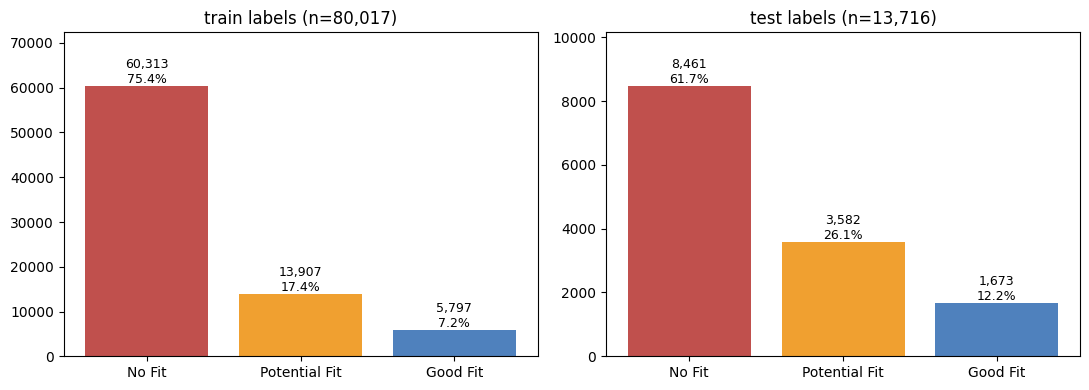


source x label (train), row %
label            No Fit  Potential Fit  Good Fit
source                                          
generated_smart    75.4           17.4       7.2

domain match x label (train), row %
col_0         No Fit  Potential Fit  Good Fit
row_0                                        
cross domain    89.2            8.8       2.0
same domain     63.5           24.8      11.7
same domain     43060
cross domain    36957

source x label (test), row %
label           No Fit  Potential Fit  Good Fit
source                                         
synthetic_test    61.7           26.1      12.2

domain match x label (test), row %
col_0         No Fit  Potential Fit  Good Fit
row_0                                        
cross domain    75.8           19.1       5.1
same domain     51.1           31.4      17.5
same domain     7840
cross domain    5876


[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (985 > 512). Running this sequence through the model will result in indexing errors



resume: n=643 | median=1039 | p90=1838 | max=4340
  over 256 tokens: 99.8%
  over 384 tokens: 98.3%
  over 512 tokens: 93.9%

JD: n=351 | median=422 | p90=947 | max=1604
  over 256 tokens: 74.4%
  over 384 tokens: 58.4%
  over 512 tokens: 40.2%


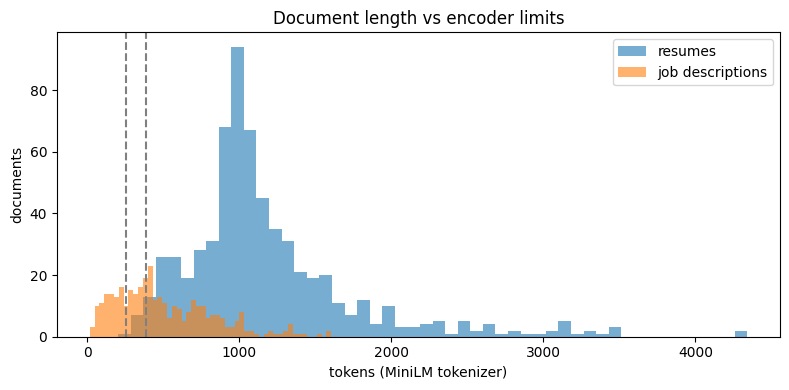

In [ ]:
# ---- 1) label distribution per split ----
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, (name, df) in zip(axes, [("train", train_df), ("test", test_df)]):
    counts = df["label"].value_counts().reindex(LABELS, fill_value=0)
    ax.bar(counts.index, counts.values, color=["#c0504d", "#f0a030", "#4f81bd"])
    ax.set_title(f"{name} labels (n={len(df):,})")
    for i, v in enumerate(counts.values):
        ax.text(i, v, f"{v:,}\n{v / len(df):.1%}", ha="center", va="bottom", fontsize=9)
    ax.set_ylim(0, counts.max() * 1.2)
plt.tight_layout()
plt.savefig(f"{CFG['out_dir']}/fig_label_distribution.png", dpi=150)
plt.show()

# ---- 2) how each source is labelled, and 3) whether domain mismatch alone predicts the label ----
for name, df in [("train", train_df), ("test", test_df)]:
    print(f"\nsource x label ({name}), row %")
    print((pd.crosstab(df["source"], df["label"], normalize="index") * 100).round(1).reindex(columns=LABELS))

    match = pd.Series(np.where(df["resume_domain"] == df["jd_domain"], "same domain", "cross domain"))
    print(f"\ndomain match x label ({name}), row %")
    print((pd.crosstab(match, df["label"].values, normalize="index") * 100).round(1).reindex(columns=LABELS))
    print(match.value_counts().to_string())

# ---- 4) token lengths on unique documents, against the encoder limits ----
tok = AutoTokenizer.from_pretrained(CFG["tokenizer_ckpt"])
both = pd.concat([train_df, test_df])
uniq_resumes = both.drop_duplicates("resume_id")["resume"].tolist()
uniq_jds = both.drop_duplicates("jd_id")["jd"].tolist()


def token_lengths(texts):
    return np.array([len(ids) for ids in tok(texts, add_special_tokens=True, truncation=False)["input_ids"]])


res_len, jd_len = token_lengths(uniq_resumes), token_lengths(uniq_jds)

for name, lens in [("resume", res_len), ("JD", jd_len)]:
    print(f"\n{name}: n={len(lens):,} | median={np.median(lens):.0f} | p90={np.percentile(lens, 90):.0f} | max={lens.max()}")
    for limit in (256, 384, 512):
        print(f"  over {limit} tokens: {(lens > limit).mean():.1%}")

fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(res_len, bins=50, alpha=0.6, label="resumes")
ax.hist(jd_len, bins=50, alpha=0.6, label="job descriptions")
for limit in (256, 384):
    ax.axvline(limit, linestyle="--", color="grey")
ax.set_xlabel("tokens (MiniLM tokenizer)")
ax.set_ylabel("documents")
ax.set_title("Document length vs encoder limits")
ax.legend()
plt.tight_layout()
plt.savefig(f"{CFG['out_dir']}/fig_token_lengths.png", dpi=150)
plt.show()

## **CELL 1.5 · Label agreement (Qwen vs original) and save everything**


> Every training label comes from an LLM, which is the biggest validity risk in the report (Section 11.1). This cell measures that risk instead of only stating it. The original public dataset is one of the merged corpus’s sources and still carries its original labels. We clean it with the same pipeline, hash-match its resume–JD pairs against the merged data, and compare the labels on identical pairs.

>The output includes raw agreement, Cohen’s kappa (agreement corrected for chance), quadratic-weighted kappa (which counts No Fit vs Good Fit disagreements as worse than neighbouring-class ones), the rate of two-class jumps, a confusion table and a few disagreeing examples to read by hand. It also measures resume overlap between the original train and test splits, which is direct evidence of the inherited leak.

>limit: agreement shows how consistent the two label sources are, not which one is right. Finally, the cleaned splits are saved as parquet, and every Part 1 number goes into audit_summary.json, so the report’s dataset section can state measured figures instead of plans.



In [ ]:
def standardise_orig(ds, split):
    df = ds.to_pandas().rename(columns={"resume_text": "resume", "job_description_text": "jd"})
    df["label"] = df["label"].astype(str).str.strip().str.title()
    unknown = set(df["label"].unique()) - set(LABELS)
    assert not unknown, f"Unexpected labels in original {split}: {unknown}"
    df["orig_split"] = split
    return df[["resume", "jd", "label", "orig_split"]]


# ---- load the upstream dataset and run it through the exact same cleaning ----
orig_raw = load_dataset(CFG["orig_dataset_id"])
print(orig_raw)
orig_df = pd.concat([standardise_orig(orig_raw[s], s) for s in orig_raw], ignore_index=True)
orig_df["resume"] = orig_df["resume"].map(clean_text)
orig_df["jd"] = orig_df["jd"].map(clean_text)
orig_df = add_ids(orig_df).drop_duplicates("pair_id").reset_index(drop=True)

# the leak inside the original split, measured directly
o_train = set(orig_df.loc[orig_df["orig_split"] == "train", "resume_id"])
o_test = orig_df[orig_df["orig_split"] == "test"]
orig_leak = float(o_test["resume_id"].isin(o_train).mean()) if len(o_test) else None
print(f"\noriginal test rows whose resume is also in original train: {orig_leak:.1%}")

# ---- find the same resume+JD pairs inside the merged data ----
merged_all = pd.concat([train_df.assign(merged_split="train"), test_df.assign(merged_split="test")])
matched = orig_df.merge(merged_all[["pair_id", "label", "source", "merged_split"]],
                        on="pair_id", suffixes=("_orig", "_qwen"))
print(f"original pairs found in merged data: {len(matched):,} of {len(orig_df):,} ({len(matched) / len(orig_df):.1%})")

agreement = {}
if len(matched):
    print("matched rows by merged source:\n" + matched["source"].value_counts().to_string())
    y_o = matched["label_orig"].map(LABEL2ID)
    y_q = matched["label_qwen"].map(LABEL2ID)
    agreement = {
        "matched_pairs": int(len(matched)),
        "exact_agreement": float((y_o == y_q).mean()),
        "cohen_kappa": float(cohen_kappa_score(y_o, y_q)),
        "weighted_kappa_quadratic": float(cohen_kappa_score(y_o, y_q, weights="quadratic")),
        "two_class_jumps": float(((y_o - y_q).abs() == 2).mean()),   # No Fit <-> Good Fit
    }
    print("\n" + json.dumps(agreement, indent=2))
    print("\nrows = original label, columns = Qwen label")
    print(pd.crosstab(matched["label_orig"], matched["label_qwen"]).reindex(index=LABELS, columns=LABELS, fill_value=0))

    # a few disagreements worth reading by hand
    for _, r in matched[y_o != y_q].head(3).iterrows():
        print(f"\noriginal: {r['label_orig']} | qwen: {r['label_qwen']}")
        print("RESUME:", r["resume"][:250].replace("\n", " "), "...")
        print("JD:    ", r["jd"][:250].replace("\n", " "), "...")
else:
    print("No overlapping pairs found; the merged data may have altered the original text.")

# ---- save cleaned splits + every audit number for the report ----
train_df.to_parquet(f"{CFG['out_dir']}/train_clean.parquet", index=False)
test_df.to_parquet(f"{CFG['out_dir']}/test_clean.parquet", index=False)

audit_summary = {
    "dataset_id": CFG["dataset_id"],
    "seed": CFG["seed"],
    "after_cleaning": {"train_rows": len(train_df), "test_rows": len(test_df)},
    "split_audit": audit,
    "train_label_share": train_df["label"].value_counts(normalize=True).round(4).to_dict(),
    "test_label_share": test_df["label"].value_counts(normalize=True).round(4).to_dict(),
    "tokens": {
        "resume_median": float(np.median(res_len)), "resume_p90": float(np.percentile(res_len, 90)),
        "jd_median": float(np.median(jd_len)), "jd_p90": float(np.percentile(jd_len, 90)),
        "resume_over_256": float((res_len > 256).mean()), "resume_over_384": float((res_len > 384).mean()),
    },
    "original_split_resume_leak": orig_leak,
    "label_agreement_vs_original": agreement,
}
with open(f"{CFG['out_dir']}/audit_summary.json", "w") as f:
    json.dump(audit_summary, f, indent=2)

print("\nsaved:", os.listdir(CFG["out_dir"]))
print(json.dumps(audit_summary, indent=2))

train.csv: reconstructing file:   0%|          |  0.00B / 53.4MB            

train.csv: downloading bytes:           |  0.00B            

test.csv: reconstructing file:   0%|          |  0.00B / 15.2MB            

test.csv: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/6241 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/1759 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['resume_text', 'job_description_text', 'label'],
        num_rows: 6241
    })
    test: Dataset({
        features: ['resume_text', 'job_description_text', 'label'],
        num_rows: 1759
    })
})

original test rows whose resume is also in original train: 99.9%
original pairs found in merged data: 1,004 of 7,993 (12.6%)
matched rows by merged source:
source
synthetic_test    1004

{
  "matched_pairs": 1004,
  "exact_agreement": 0.39641434262948205,
  "cohen_kappa": 0.06867842967375948,
  "weighted_kappa_quadratic": 0.1718403860314277,
  "two_class_jumps": 0.14840637450199204
}

rows = original label, columns = Qwen label
label_qwen     No Fit  Potential Fit  Good Fit
label_orig                                    
No Fit            245            138        41
Potential Fit     126             98        63
Good Fit          108            130        55

original: No Fit | qwen: Good Fit
RESUME: Summary Seeking an accounting posit

# ***Part 2: Leakage-Free Split and Baselines***

## **CELL 2.1 : Leakage-free split: resume-disjoint 80/10/10 + unseen-JD test**
>This cell builds the evaluation protocol (report Section 4.7). First, 10% of job descriptions are held out completely: every pair using one of them goes to jd_test, which measures performance on unseen vacancies. The remaining pairs are split 80/10/10 with StratifiedGroupKFold, grouped by resume, so each resume appears in exactly one of train, validation and test, and every part keeps a similar label mix. The provided test split stays as test_orig, as a reference only. Assertions stop the notebook if anything leaks.

>The split is deterministic (fixed seed), so rerunning this cell after a restart rebuilds exactly the same split. It also defines the helpers every later part uses: score() (accuracy, macro F1, and row-level predictions saved to Drive), results_table() and load_preds(). Results are stored in results.json, so they survive restarts.

In [ ]:
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import f1_score, accuracy_score

base = pd.read_parquet(f"{CFG['out_dir']}/train_clean.parquet")
test_orig = pd.read_parquet(f"{CFG['out_dir']}/test_clean.parquet")   # provided test, reference only
rng = np.random.default_rng(CFG["seed"])

# 1) lock away 10% of job descriptions entirely -> performance on vacancies never seen in training
jds = np.sort(base["jd_id"].unique())
held = set(rng.choice(jds, size=max(1, int(0.10 * len(jds))), replace=False))
jd_test = base[base["jd_id"].isin(held)]
rest = base[~base["jd_id"].isin(held)].reset_index(drop=True)

# 2) resume-disjoint 80/10/10 on the rest: each resume lives in one part, label shares kept similar
sgkf = StratifiedGroupKFold(n_splits=10, shuffle=True, random_state=CFG["seed"])
folds = [idx for _, idx in sgkf.split(rest, rest["label_id"], groups=rest["resume_id"])]

SPLITS = {
    "train": rest.drop(index=np.concatenate(folds[:2])),
    "val": rest.iloc[folds[1]],
    "test": rest.iloc[folds[0]],
    "jd_test": jd_test,
    "test_orig": test_orig,
}
SPLITS = {k: v.reset_index(drop=True) for k, v in SPLITS.items()}
EVAL_SPLITS = ["val", "test", "jd_test", "test_orig"]

# 3) prove it: overlap with train, size and label mix per split
tr_res, tr_jd = set(SPLITS["train"]["resume_id"]), set(SPLITS["train"]["jd_id"])


def describe(df, name):
    d = {"pairs": len(df), "resumes": df["resume_id"].nunique(), "jds": df["jd_id"].nunique()}
    if name != "train":
        d["resume_in_train"] = df["resume_id"].isin(tr_res).mean()
        d["jd_in_train"] = df["jd_id"].isin(tr_jd).mean()
    return d | df["label"].value_counts(normalize=True).reindex(LABELS, fill_value=0).to_dict()


split_report = pd.DataFrame({n: describe(d, n) for n, d in SPLITS.items()}).T
assert split_report.loc["val", "resume_in_train"] == 0 and split_report.loc["test", "resume_in_train"] == 0
assert split_report.loc["jd_test", "jd_in_train"] == 0
split_report.to_csv(f"{CFG['out_dir']}/split_report.csv")

# ---- scoring helpers used by every model; results persist in Drive across restarts ----
RESULTS_PATH = f"{CFG['out_dir']}/results.json"
RESULTS = json.load(open(RESULTS_PATH)) if os.path.exists(RESULTS_PATH) else {}


def score(model_name, split, pred, proba=None, extra=None):
    df = SPLITS[split]
    RESULTS.setdefault(model_name, {})[split] = {
        "acc": float(accuracy_score(df["label_id"], pred)),
        "macro_f1": float(f1_score(df["label_id"], pred, average="macro")),
    }
    # row-level predictions, so Part 4 can slice by source/domain without retraining
    out = df[["pair_id", "resume_id", "jd_id", "label_id", "source", "resume_domain", "jd_domain"]].copy()
    out["pred"] = pred
    if proba is not None:
        out[[f"p{i}" for i in range(len(LABELS))]] = proba
    if extra:
        out = out.assign(**extra)
    out.to_parquet(f"{CFG['out_dir']}/preds_{model_name}_{split}.parquet", index=False)


def results_table(metric="macro_f1"):
    with open(RESULTS_PATH, "w") as f:
        json.dump(RESULTS, f, indent=2)
    return pd.DataFrame({m: {s: v[metric] for s, v in d.items()} for m, d in RESULTS.items()}).T.round(4)


def load_preds(model_name, split):
    return pd.read_parquet(f"{CFG['out_dir']}/preds_{model_name}_{split}.parquet")


split_report.round(3)

,pairs,resumes,jds,No Fit,Potential Fit,Good Fit,resume_in_train,jd_in_train
train,57519.0,513.0,252.0,0.757,0.169,0.073,NaN,NaN
val,6683.0,63.0,252.0,0.729,0.188,0.083,0.000,1.0
test,7500.0,66.0,252.0,0.729,0.179,0.092,0.000,1.0
jd_test,8315.0,642.0,28.0,0.771,0.189,0.041,0.801,0.0
test_orig,13716.0,477.0,71.0,0.617,0.261,0.122,0.783,0.0


## **CELL 2.2 : Baseline C: TF-IDF overlap features + logistic regression**

This is the lexical baseline (Baseline C). TF-IDF over unigrams and bigrams (30,000 terms) is fitted on training documents only. Each pair is described by the weight of every term the resume and JD share, plus four summary signals:

*   cosine similarity between the two documents;
*   JD coverage: how much of the JD’s term weight appears in the resume;
*   resume relevance: how much of the resume is on-topic for the JD;
*   shared terms: how many terms the two have in common.

Coverage matters because a short resume can match well on cosine while missing most of what the JD asks for. Each unique document is vectorised once and reused, which keeps memory and runtime low. A class-weighted logistic regression handles the imbalance. If the fine-tuned model can’t beat this, the transformer adds no semantic value (RQ2).

In [ ]:
import time
from scipy.sparse import hstack, csr_matrix
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression

# vocabulary comes from unique training documents only, nothing from val/test
train_docs = pd.concat([SPLITS["train"]["resume"], SPLITS["train"]["jd"]]).drop_duplicates()
tfidf = TfidfVectorizer(sublinear_tf=True, ngram_range=(1, 2), min_df=2, max_features=30_000,
                        stop_words="english", dtype=np.float32)
tfidf.fit(train_docs)


def doc_rows(df, text_col, id_col):
    # vectorise each unique document once, then index into it; pairs reuse the same docs a lot
    uniq = df.drop_duplicates(id_col)
    pos = pd.Series(np.arange(len(uniq)), index=uniq[id_col].values)
    return tfidf.transform(uniq[text_col])[pos.loc[df[id_col]].to_numpy()]


def tfidf_feats(df):
    R, J = doc_rows(df, "resume", "resume_id"), doc_rows(df, "jd", "jd_id")
    overlap = R.multiply(J).tocsr()                              # weight of each shared term
    cos = np.asarray(overlap.sum(axis=1))                        # rows are L2-normed -> cosine
    jd_cov = np.asarray(J.multiply(R > 0).sum(axis=1))           # share of the JD's weight the resume covers
    res_cov = np.asarray(R.multiply(J > 0).sum(axis=1))          # share of the resume on-topic for the JD
    shared = np.asarray((overlap > 0).sum(axis=1))               # number of shared terms
    dense = np.hstack([cos, jd_cov, res_cov, np.log1p(shared)])
    return hstack([overlap, csr_matrix(dense)]).tocsr()


t0 = time.time()
X_tr = tfidf_feats(SPLITS["train"])
print(f"train matrix: {X_tr.shape[0]:,} x {X_tr.shape[1]:,}, {X_tr.nnz:,} non-zeros")

tfidf_clf = LogisticRegression(max_iter=2000, C=4.0, class_weight="balanced")
tfidf_clf.fit(X_tr, SPLITS["train"]["label_id"])
print(f"fitted in {time.time() - t0:.0f}s")

for split in EVAL_SPLITS:
    X = tfidf_feats(SPLITS[split])
    score("tfidf_logreg", split, tfidf_clf.predict(X), tfidf_clf.predict_proba(X))

results_table()

train matrix: 57,519 x 30,004, 2,061,840 non-zeros
fitted in 42s


,val,test,jd_test,test_orig
tfidf_logreg,0.5010,0.5124,0.4252,0.5393
minilm_cosine,0.4610,0.4579,0.4388,0.5223
minilm_frozen_head,0.6082,0.5984,0.5080,0.5649
sbert_finetuned,0.7698,0.7580,0.6391,0.6762


## **CELL 2.3 : Baseline A: pretrained MiniLM (no fine-tuning) with chunked encoding.**

This is Baseline A: pretrained all-MiniLM-L6-v2, with no fine-tuning. Documents longer than the 256-token limit are split into overlapping 254-token windows. Each window is encoded and the vectors are averaged into one document embedding, so nothing is lost to truncation.

Two versions are scored:

*   minilm_cosine turns cosine similarity alone into a 3-class decision. That’s the classic “embed and compare” approach (RQ1).
*   minilm_frozen_head gives a linear classifier the same interaction features the proposed model uses (cosine, |R − J|, R ⊙ J), with the encoder frozen.

Part 3 has to beat minilm_frozen_head to show that fine-tuning the encoder adds value (RQ2). The encoder is freed afterwards to leave GPU memory for training.

>The final table ranks all three baselines across validation, the resume-disjoint test, the unseen-JD test and the provided test. Part 3 has to beat minilm_frozen_head to show that fine-tuning the encoder itself adds value, which is research question RQ2.

In [ ]:
from sentence_transformers import SentenceTransformer

CFG.update({"encoder": "sentence-transformers/all-MiniLM-L6-v2", "chunk_tokens": 256, "chunk_stride": 192})

encoder = SentenceTransformer(CFG["encoder"], device=str(DEVICE))
encoder.max_seq_length = CFG["chunk_tokens"]


def chunk_text(text, size=CFG["chunk_tokens"], stride=CFG["chunk_stride"]):
    # overlapping token windows so nothing past the first 256 tokens is thrown away
    ids = encoder.tokenizer(text, add_special_tokens=False)["input_ids"]
    body = size - 2                                       # room for [CLS] and [SEP]
    if len(ids) <= body:
        return [text]
    starts = list(range(0, len(ids) - body, stride)) + [len(ids) - body]
    return [encoder.tokenizer.decode(ids[s:s + body]) for s in starts]


def embed_docs(id_text):
    chunks, owner = [], []
    for i, text in enumerate(id_text.values()):
        cs = chunk_text(text)
        chunks += cs
        owner += [i] * len(cs)
    E = encoder.encode(chunks, batch_size=128, convert_to_numpy=True, normalize_embeddings=True, show_progress_bar=True)
    owner = np.array(owner)
    doc = np.zeros((len(id_text), E.shape[1]), dtype=np.float32)
    np.add.at(doc, owner, E)                              # mean-pool the chunks of each document
    doc /= np.linalg.norm(doc, axis=1, keepdims=True)
    return dict(zip(id_text.keys(), doc))


# every unique resume and JD across all splits, encoded once
everything = pd.concat(SPLITS.values())
EMB = embed_docs({**dict(zip(everything["resume_id"], everything["resume"])),
                  **dict(zip(everything["jd_id"], everything["jd"]))})


def pair_feats(df, full=True):
    R, J = np.stack(df["resume_id"].map(EMB)), np.stack(df["jd_id"].map(EMB))
    cos = (R * J).sum(axis=1, keepdims=True)
    return np.hstack([cos, np.abs(R - J), R * J]) if full else cos


# A1: cosine similarity alone, thresholds learned by a tiny classifier
# A2: frozen embeddings + the same interaction features the proposed model uses, linear head only
for name, full in [("minilm_cosine", False), ("minilm_frozen_head", True)]:
    clf = LogisticRegression(max_iter=3000, class_weight="balanced")
    clf.fit(pair_feats(SPLITS["train"], full), SPLITS["train"]["label_id"])
    for split in EVAL_SPLITS:
        X = pair_feats(SPLITS[split], full)
        score(name, split, clf.predict(X), clf.predict_proba(X))

print(f"{len(EMB):,} unique documents encoded")
del encoder
torch.cuda.empty_cache()
results_table()

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (1023 > 256). Running this sequence through the model will result in indexing errors


Batches:   0%|          | 0/40 [00:00<?, ?it/s]

994 unique documents encoded


,val,test,jd_test,test_orig
tfidf_logreg,0.5010,0.5124,0.4252,0.5393
minilm_cosine,0.4610,0.4579,0.4388,0.5223
minilm_frozen_head,0.6082,0.5984,0.5080,0.5649
sbert_finetuned,0.7698,0.7580,0.6391,0.6762


## ***Part 3: Proposed Model, Fine-Tuned SBERT Bi-Encoder***

## **CELL 3.1 · Configuration, chunked tokenisation and batch builder**

>This cell sets the training configuration and prepares the input pipeline. Each unique document is tokenised once into overlapping 256-token windows, with 64 tokens of overlap. Documents longer than six windows keep six evenly spaced windows, so the whole document is still sampled rather than just its beginning. The printed cap rate belongs in the limitations section. make_batch collects the unique documents in each batch of pairs, encodes each one only once, and records which resume and JD each pair uses. Since D1 reuses the same documents across many pairs, this saves a large share of the computation.

In [ ]:
import torch.nn as nn
import torch.nn.functional as F
from transformers import AutoModel, get_linear_schedule_with_warmup
from tqdm.auto import tqdm

CFG.update({
    "encoder": "sentence-transformers/all-MiniLM-L6-v2",
    "chunk_tokens": 256, "chunk_stride": 192, "max_chunks": 6,   # up to 6 overlapping windows per document
    "batch_size": 32, "epochs": 3, "patience": 1,
    "lr_encoder": 2e-5, "lr_head": 1e-3, "weight_decay": 0.01, "warmup": 0.06,
    "head_hidden": 256, "dropout": 0.1,
    "ckpt": f"{CFG['out_dir']}/sbert_matcher_best.pt",
})
TOK = AutoTokenizer.from_pretrained(CFG["encoder"])


def to_chunks(text):
    # token windows with overlap; very long documents keep evenly spaced windows so the whole text is sampled
    ids = TOK(text, add_special_tokens=False, truncation=False)["input_ids"]
    body = CFG["chunk_tokens"] - 2
    if len(ids) <= body:
        starts = [0]
    else:
        starts = list(range(0, len(ids) - body, CFG["chunk_stride"])) + [len(ids) - body]
        if len(starts) > CFG["max_chunks"]:
            keep = np.linspace(0, len(starts) - 1, CFG["max_chunks"]).round().astype(int)
            starts = [starts[k] for k in keep]
    return [[TOK.cls_token_id] + ids[s:s + body] + [TOK.sep_token_id] for s in starts]


# tokenise every unique document once; batches then only pad and stack
everything = pd.concat(SPLITS.values())
DOC_TEXT = {**dict(zip(everything["resume_id"], everything["resume"])), **dict(zip(everything["jd_id"], everything["jd"]))}
DOC_CHUNKS = {d: to_chunks(t) for d, t in tqdm(DOC_TEXT.items(), desc="tokenising")}


def pack(doc_ids, cache):
    # all chunks of the given documents in one padded tensor, plus which document each chunk belongs to
    seqs, owner = [], []
    for i, d in enumerate(doc_ids):
        seqs += cache[d]
        owner += [i] * len(cache[d])
    ids = torch.full((len(seqs), max(map(len, seqs))), TOK.pad_token_id, dtype=torch.long)
    att = torch.zeros_like(ids)
    for k, s in enumerate(seqs):
        ids[k, :len(s)] = torch.tensor(s)
        att[k, :len(s)] = 1
    return ids, att, torch.tensor(owner)


def make_batch(rows):
    # pairs share documents a lot, so each unique document in the batch is encoded only once
    docs = list(dict.fromkeys([*rows["resume_id"], *rows["jd_id"]]))
    pos = {d: i for i, d in enumerate(docs)}
    ids, att, owner = pack(docs, DOC_CHUNKS)
    return {
        "input_ids": ids.to(DEVICE), "attention_mask": att.to(DEVICE), "owner": owner.to(DEVICE), "n_docs": len(docs),
        "r_idx": torch.tensor([pos[x] for x in rows["resume_id"]], device=DEVICE),
        "j_idx": torch.tensor([pos[x] for x in rows["jd_id"]], device=DEVICE),
        "labels": torch.tensor(rows["label_id"].to_numpy(), device=DEVICE),
    }


n_chunks = pd.Series({d: len(c) for d, c in DOC_CHUNKS.items()})
print(f"{len(DOC_CHUNKS):,} documents | chunks per doc: mean {n_chunks.mean():.2f}, max {n_chunks.max()} "
      f"| docs hitting the {CFG['max_chunks']}-window cap: {(n_chunks == CFG['max_chunks']).mean():.1%}")

tokenising:   0%|          | 0/994 [00:00<?, ?it/s]

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (1023 > 512). Running this sequence through the model will result in indexing errors


994 documents | chunks per doc: mean 4.30, max 6 | docs hitting the 6-window cap: 36.0%


## **CELL 3.2 : Model: shared SBERT encoder -> interaction features -> MLP head**

>This is the proposed architecture (report Section 7.3). One MiniLM encoder with shared weights encodes both the resume and the JD. Each window is mean-pooled over its tokens (the SBERT pooling), the windows are averaged into a document vector, and the result is L2-normalised. Each pair is then described by cosine similarity, the absolute difference |R − J| and the element-wise product R ⊙ J, and a two-layer MLP (256 hidden units, GELU, dropout 0.1) outputs three logits. Gradients from both branches update the same encoder.

>For inference, embed_texts embeds each document once and predict_pairs runs only the light classification head for each pair. That makes scoring tens of thousands of pairs fast, which Part 5’s 60,884 PopResume resumes need. load_model restores the best saved checkpoint after a restart.

In [ ]:
class BiEncoderMatcher(nn.Module):
    # one encoder, shared weights for resume and JD; a small MLP turns the pair into 3 class logits
    def __init__(self, name, n_classes=len(LABELS), hidden=CFG["head_hidden"], dropout=CFG["dropout"]):
        super().__init__()
        self.encoder = AutoModel.from_pretrained(name)
        d = self.encoder.config.hidden_size
        self.head = nn.Sequential(nn.Linear(2 * d + 1, hidden), nn.GELU(), nn.Dropout(dropout), nn.Linear(hidden, n_classes))

    def embed(self, input_ids, attention_mask, owner, n_docs):
        tokens = self.encoder(input_ids=input_ids, attention_mask=attention_mask).last_hidden_state
        mask = attention_mask.unsqueeze(-1).to(tokens.dtype)
        chunk = ((tokens * mask).sum(1) / mask.sum(1).clamp(min=1e-9)).float()       # SBERT mean pooling
        doc = torch.zeros(n_docs, chunk.size(1), device=chunk.device).index_add_(0, owner, chunk)
        doc = doc / torch.bincount(owner, minlength=n_docs).unsqueeze(1)             # average the windows
        return F.normalize(doc, dim=-1)

    def classify(self, r, j):
        feats = torch.cat([(r * j).sum(-1, keepdim=True), (r - j).abs(), r * j], dim=-1)  # cosine, |R-J|, R*J
        return self.head(feats)

    def forward(self, b):
        emb = self.embed(b["input_ids"], b["attention_mask"], b["owner"], b["n_docs"])
        return self.classify(emb[b["r_idx"]], emb[b["j_idx"]])


USE_AMP = DEVICE.type == "cuda"


@torch.no_grad()
def embed_texts(model, id_text, docs_per_batch=32):
    # document embeddings for any texts; known documents reuse their cached tokens
    model.eval()
    cache = {d: DOC_CHUNKS[d] if d in DOC_CHUNKS else to_chunks(t) for d, t in id_text.items()}
    keys, out = list(id_text), []
    for b in range(0, len(keys), docs_per_batch):
        part = keys[b:b + docs_per_batch]
        ids, att, owner = pack(part, cache)
        with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=USE_AMP):
            out.append(model.embed(ids.to(DEVICE), att.to(DEVICE), owner.to(DEVICE), len(part)).float().cpu())
    return dict(zip(keys, torch.cat(out)))


@torch.no_grad()
def predict_pairs(model, df, emb=None, bs=2048):
    # class probabilities + cosine for every pair; documents are embedded once, the head runs per pair
    model.eval()
    if emb is None:
        emb = embed_texts(model, {**dict(zip(df["resume_id"], df["resume"])), **dict(zip(df["jd_id"], df["jd"]))})
    R = torch.stack([emb[x] for x in df["resume_id"]])
    J = torch.stack([emb[x] for x in df["jd_id"]])
    probs = torch.cat([torch.softmax(model.classify(R[b:b + bs].to(DEVICE), J[b:b + bs].to(DEVICE)).float(), -1).cpu()
                       for b in range(0, len(df), bs)])
    return probs.numpy(), (R * J).sum(-1).numpy()


def load_model():
    m = BiEncoderMatcher(CFG["encoder"]).to(DEVICE)
    m.load_state_dict(torch.load(CFG["ckpt"], map_location=DEVICE))
    return m.eval()


n_params = sum(p.numel() for p in BiEncoderMatcher(CFG["encoder"]).parameters())
print(f"model parameters: {n_params / 1e6:.1f}M")

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

model parameters: 22.9M


## **CELL 3.3 : Training: class-weighted loss, AMP, warm-up, early stopping on validation macro F1**

>This cell fine-tunes the whole model end to end (report Section 8.4).

>Loss: cross-entropy weighted by inverse class frequency, so minority classes count.
>Optimiser: AdamW with two learning rates: 2e-5 for the pretrained encoder, so its language knowledge isn’t overwritten, and 1e-3 for the freshly initialised head.
>Schedule: linear, with warm-up over the first 6% of steps.
>Speed: mixed precision (AMP) halves memory use and speeds up the T4. Gradients are clipped at 1.0.

>After every epoch the model is scored on validation only. The best checkpoint by validation macro F1 is saved to Drive, and training stops early if validation stops improving. The test splits are used once, by the best checkpoint, after training ends. The final table compares the fine-tuned model with all three baselines. Expect roughly 30 to 60 minutes on a T4.

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

class weights: {'No Fit': 0.4399999976158142, 'Potential Fit': 1.9700000286102295, 'Good Fit': 4.547999858856201}


epoch 1:   0%|          | 0/1798 [00:00<?, ?it/s]

{'epoch': 1, 'train_loss': 0.6184217582588334, 'val_macro_f1': 0.7547121615055907, 'minutes': 16.9}


epoch 2:   0%|          | 0/1798 [00:00<?, ?it/s]

{'epoch': 2, 'train_loss': 0.4137316437415339, 'val_macro_f1': 0.7596983620105008, 'minutes': 33.9}


epoch 3:   0%|          | 0/1798 [00:00<?, ?it/s]

{'epoch': 3, 'train_loss': 0.33922555323511994, 'val_macro_f1': 0.7692220166867937, 'minutes': 50.8}


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

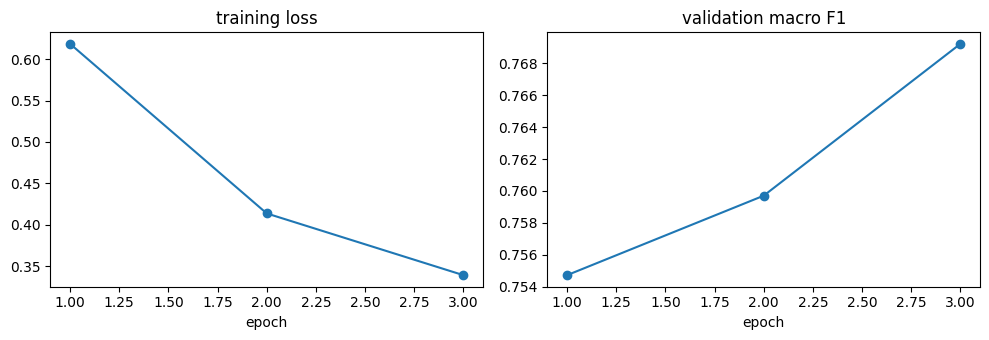

,val,test,jd_test,test_orig
tfidf_logreg,0.5010,0.5124,0.4252,0.5393
minilm_cosine,0.4610,0.4579,0.4388,0.5223
minilm_frozen_head,0.6082,0.5984,0.5080,0.5649
sbert_finetuned,0.7692,0.7555,0.6346,0.6731


In [ ]:
import math
set_seed(CFG["seed"])
model = BiEncoderMatcher(CFG["encoder"]).to(DEVICE)
train = SPLITS["train"]

counts = np.bincount(train["label_id"], minlength=len(LABELS))
class_w = torch.tensor(counts.sum() / (len(LABELS) * counts), dtype=torch.float, device=DEVICE)
loss_fn = nn.CrossEntropyLoss(weight=class_w)
print("class weights:", dict(zip(LABELS, class_w.round(decimals=3).tolist())))

# the pretrained encoder moves slowly, the fresh head learns fast
opt = torch.optim.AdamW([{"params": model.encoder.parameters(), "lr": CFG["lr_encoder"]},
                         {"params": model.head.parameters(), "lr": CFG["lr_head"]}], weight_decay=CFG["weight_decay"])
total_steps = math.ceil(len(train) / CFG["batch_size"]) * CFG["epochs"]
sched = get_linear_schedule_with_warmup(opt, int(CFG["warmup"] * total_steps), total_steps)
scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)

rng = np.random.default_rng(CFG["seed"])
history, best, bad, t0 = [], -1.0, 0, time.time()
for epoch in range(1, CFG["epochs"] + 1):
    model.train()
    perm, running = rng.permutation(len(train)), 0.0
    bar = tqdm(range(0, len(train), CFG["batch_size"]), desc=f"epoch {epoch}")
    for step, b in enumerate(bar, 1):
        batch = make_batch(train.iloc[perm[b:b + CFG["batch_size"]]])
        with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=USE_AMP):
            logits = model(batch)
        loss = loss_fn(logits.float(), batch["labels"])
        opt.zero_grad(set_to_none=True)
        scaler.scale(loss).backward()
        scaler.unscale_(opt)
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        scaler.step(opt)
        scaler.update()
        sched.step()
        running += loss.item()
        if step % 50 == 0:
            bar.set_postfix(loss=f"{running / step:.4f}")

    probs, _ = predict_pairs(model, SPLITS["val"])
    val_f1 = f1_score(SPLITS["val"]["label_id"], probs.argmax(1), average="macro")
    history.append({"epoch": epoch, "train_loss": running / step, "val_macro_f1": float(val_f1),
                    "minutes": round((time.time() - t0) / 60, 1)})
    print(history[-1])
    if val_f1 > best:
        best, bad = val_f1, 0
        torch.save(model.state_dict(), CFG["ckpt"])
    else:
        bad += 1
        if bad > CFG["patience"]:
            print("early stopping: validation macro F1 stopped improving")
            break

CFG["train_minutes"] = round((time.time() - t0) / 60, 1)
json.dump(history, open(f"{CFG['out_dir']}/train_history.json", "w"), indent=2)

# best checkpoint -> score every evaluation split once
model = load_model()
for split in EVAL_SPLITS:
    probs, cos = predict_pairs(model, SPLITS[split])
    score("sbert_finetuned", split, probs.argmax(1), probs, extra={"cos": cos})

h = pd.DataFrame(history)
fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
ax[0].plot(h["epoch"], h["train_loss"], marker="o"); ax[0].set_title("training loss"); ax[0].set_xlabel("epoch")
ax[1].plot(h["epoch"], h["val_macro_f1"], marker="o"); ax[1].set_title("validation macro F1"); ax[1].set_xlabel("epoch")
plt.tight_layout(); plt.savefig(f"{CFG['out_dir']}/fig_training_curves.png", dpi=150); plt.show()

results_table()

# ***Part 4: Evaluation***

## **CELL 4.1 : Model comparison, per-class report and confusion matrices**

>These are the headline results (report Sections 10.1–10.2). The cell reports macro F1 and accuracy for every model on every split, saved as CSV. For the fine-tuned model it adds a per-class report (precision, recall and F1 for each class) on the resume-disjoint test and the unseen-JD test. It also gives the rate of two-class errors: predicting Good Fit for a No Fit pair, or the reverse, which is the most harmful mistake in screening. Row-normalised confusion matrices show where the errors go. Potential Fit should be the hardest class, since it sits between the other two.

macro F1


,val,test,jd_test,test_orig
tfidf_logreg,0.5010,0.5124,0.4252,0.5393
minilm_cosine,0.4610,0.4579,0.4388,0.5223
minilm_frozen_head,0.6082,0.5984,0.5080,0.5649
sbert_finetuned,0.7692,0.7555,0.6346,0.6731


accuracy


,val,test,jd_test,test_orig
tfidf_logreg,0.6207,0.6421,0.6184,0.6180
minilm_cosine,0.5960,0.5973,0.6415,0.6177
minilm_frozen_head,0.7227,0.7049,0.6995,0.6607
sbert_finetuned,0.8577,0.8504,0.8172,0.7557



--- sbert_finetuned on test ---
               precision    recall  f1-score   support

       No Fit     0.9593    0.9020    0.9298      5467
Potential Fit     0.5793    0.7221    0.6429      1346
     Good Fit     0.6965    0.6914    0.6939       687

     accuracy                         0.8504      7500
    macro avg     0.7450    0.7718    0.7555      7500
 weighted avg     0.8670    0.8504    0.8567      7500

two-class errors (No Fit <-> Good Fit): 0.56%

--- sbert_finetuned on jd_test ---
               precision    recall  f1-score   support

       No Fit     0.9520    0.8573    0.9022      6407
Potential Fit     0.5235    0.7529    0.6176      1570
     Good Fit     0.4181    0.3550    0.3840       338

     accuracy                         0.8172      8315
    macro avg     0.6312    0.6551    0.6346      8315
 weighted avg     0.8494    0.8172    0.8274      8315

two-class errors (No Fit <-> Good Fit): 0.67%


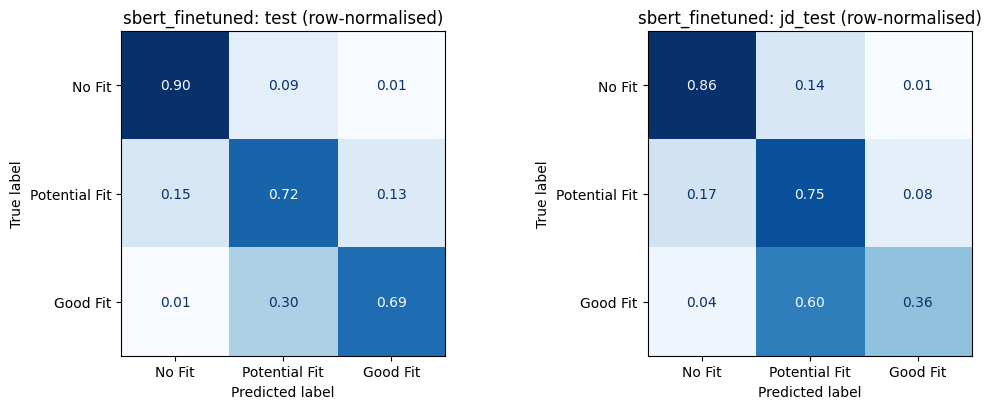

In [ ]:
from sklearn.metrics import classification_report, ConfusionMatrixDisplay

f1_tab, acc_tab = results_table("macro_f1"), results_table("acc")
print("macro F1"); display(f1_tab)
print("accuracy"); display(acc_tab)
f1_tab.to_csv(f"{CFG['out_dir']}/table_macro_f1.csv"); acc_tab.to_csv(f"{CFG['out_dir']}/table_accuracy.csv")

MAIN = "sbert_finetuned"
per_class = {}
for split in ["test", "jd_test"]:
    p = load_preds(MAIN, split)
    print(f"\n--- {MAIN} on {split} ---")
    print(classification_report(p["label_id"], p["pred"], target_names=LABELS, digits=4, zero_division=0))
    per_class[split] = classification_report(p["label_id"], p["pred"], target_names=LABELS, output_dict=True, zero_division=0)
    jumps = ((p["label_id"] - p["pred"]).abs() == 2).mean()
    print(f"two-class errors (No Fit <-> Good Fit): {jumps:.2%}")
json.dump(per_class, open(f"{CFG['out_dir']}/per_class_report.json", "w"), indent=2)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
for ax, split in zip(axes, ["test", "jd_test"]):
    p = load_preds(MAIN, split)
    ConfusionMatrixDisplay.from_predictions(p["label_id"], p["pred"], display_labels=LABELS, normalize="true",
                                            values_format=".2f", colorbar=False, ax=ax, cmap="Blues")
    ax.set_title(f"{MAIN}: {split} (row-normalised)")
plt.tight_layout(); plt.savefig(f"{CFG['out_dir']}/fig_confusion.png", dpi=150); plt.show()

## **CELL 4.2 : Slices (source, same vs cross domain) and calibration**
> Two checks behind the headline numbers.

>**Slices:** macro F1 for each data source, and for same-domain vs cross-domain pairs, for every model. If a model is strong on cross-domain pairs but weak on same-domain ones, it has mostly learned the domain shortcut found in Part 1. Same-domain performance is the realistic measure. Slices with fewer than 30 pairs are skipped as unstable.

>**Calibration:** expected calibration error (ECE) measures whether a stated 80% confidence is right about 80% of the time. A recruiter reading probabilities needs them to mean what they say. The reliability plot shows over- or under-confidence in each confidence bin.

model                                    minilm_cosine  minilm_frozen_head  \
split     slice                   n                                          
test      domain: cross domain    3269           0.410               0.534   
          domain: same domain     4231           0.458               0.602   
          source: generated_smart 7500           0.458               0.598   
test_orig domain: cross domain    5876           0.451               0.521   
          domain: same domain     7840           0.532               0.561   
          source: synthetic_test  13716          0.522               0.565   

model                                    sbert_finetuned  tfidf_logreg  
split     slice                   n                                     
test      domain: cross domain    3269             0.741         0.461  
          domain: same domain     4231             0.749         0.513  
          source: generated_smart 7500             0.756         0.512  
test_orig domain: cross domain    5876             0.591         0.467  
          domain: same domain     7840             0.681         0.550  
          source: synthetic_test  13716            0.673         0.539

expected calibration error on test (lower is better):
tfidf_logreg          0.0954
minilm_cosine         0.0824
minilm_frozen_head    0.0363
sbert_finetuned       0.0466


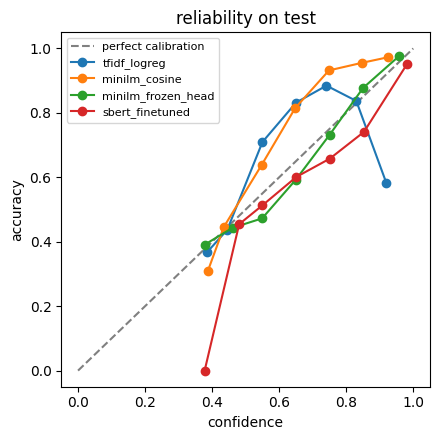

In [ ]:
rows = []
for m in RESULTS:
    for split in ["test", "test_orig"]:
        p = load_preds(m, split)
        p["domain"] = np.where(p["resume_domain"] == p["jd_domain"], "same domain", "cross domain")
        for col in ["source", "domain"]:
            for g, d in p.groupby(col):
                if len(d) >= 30:   # too few rows gives unstable numbers
                    rows.append({"split": split, "slice": f"{col}: {g}", "n": len(d), "model": m,
                                 "macro_f1": f1_score(d["label_id"], d["pred"], average="macro", zero_division=0)})
slices = pd.DataFrame(rows)
slice_tab = slices.pivot_table(index=["split", "slice", "n"], columns="model", values="macro_f1").round(3)
display(slice_tab)
slice_tab.to_csv(f"{CFG['out_dir']}/table_slices.csv")


def ece(probs, y, bins=10):
    # expected calibration error: gap between confidence and accuracy, averaged over confidence bins
    conf, hit = probs.max(1), probs.argmax(1) == y
    edges, err, curve = np.linspace(0, 1, bins + 1), 0.0, []
    for lo, hi in zip(edges[:-1], edges[1:]):
        m = (conf > lo) & (conf <= hi)
        if m.any():
            err += m.mean() * abs(hit[m].mean() - conf[m].mean())
            curve.append((conf[m].mean(), hit[m].mean()))
    return err, np.array(curve)


calib, curves = {}, {}
for m in RESULTS:
    p = load_preds(m, "test")
    calib[m], curves[m] = ece(p[["p0", "p1", "p2"]].to_numpy(), p["label_id"].to_numpy())
print("expected calibration error on test (lower is better):")
print(pd.Series(calib).round(4).to_string())

fig, ax = plt.subplots(figsize=(4.5, 4.5))
ax.plot([0, 1], [0, 1], "--", color="grey", label="perfect calibration")
for m, c in curves.items():
    ax.plot(c[:, 0], c[:, 1], marker="o", label=m)
ax.set_xlabel("confidence"); ax.set_ylabel("accuracy"); ax.set_title("reliability on test"); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig(f"{CFG['out_dir']}/fig_reliability.png", dpi=150); plt.show()

## **CELL 4.3 · Significance: resume-clustered paired bootstrap of the macro F1 gain**

>This tests whether the fine-tuned model’s macro F1 gain over each baseline is real or just sampling noise (report Section 9.6). Pairs that share a resume aren’t independent, so the bootstrap resamples whole resumes, 1,000 times, and recomputes both models’ macro F1 on each resample. The 95% interval of the difference is reported; if it excludes zero, the gain is significant at that level. The test set has only 66 unique resumes, so the intervals will be fairly wide, and that width is itself an honest finding to report.

In [ ]:
def cluster_bootstrap(model_a, model_b, split, n_boot=1000):
    # resample whole resumes (pairs of one resume are not independent), compare both models on the same sample
    pa, pb = load_preds(model_a, split), load_preds(model_b, split)
    assert (pa["pair_id"].to_numpy() == pb["pair_id"].to_numpy()).all()
    y, ya, yb = pa["label_id"].to_numpy(), pa["pred"].to_numpy(), pb["pred"].to_numpy()
    groups = list(pa.groupby("resume_id").indices.values())
    rng = np.random.default_rng(CFG["seed"])
    diffs = []
    for _ in range(n_boot):
        idx = np.concatenate([groups[g] for g in rng.integers(0, len(groups), len(groups))])
        diffs.append(f1_score(y[idx], ya[idx], average="macro") - f1_score(y[idx], yb[idx], average="macro"))
    lo, hi = np.percentile(diffs, [2.5, 97.5])
    gain = f1_score(y, ya, average="macro") - f1_score(y, yb, average="macro")
    return {"vs": model_b, "split": split, "gain": gain, "ci_low": lo, "ci_high": hi,
            "resumes": len(groups), "significant": bool(lo > 0 or hi < 0)}


sig = pd.DataFrame([cluster_bootstrap(MAIN, b, s) for b in RESULTS if b != MAIN for s in ["test", "jd_test"]])
sig[["gain", "ci_low", "ci_high"]] = sig[["gain", "ci_low", "ci_high"]].round(4)
sig.to_csv(f"{CFG['out_dir']}/table_significance.csv", index=False)
sig

,vs,split,gain,ci_low,ci_high,resumes,significant
0,tfidf_logreg,test,0.2431,0.2078,0.2758,66,True
1,tfidf_logreg,jd_test,0.2094,0.1888,0.2287,642,True
2,minilm_cosine,test,0.2976,0.2630,0.3305,66,True
3,minilm_cosine,jd_test,0.1958,0.1753,0.2158,642,True
4,minilm_frozen_head,test,0.1571,0.1286,0.1851,66,True
5,minilm_frozen_head,jd_test,0.1266,0.1071,0.1460,642,True


# ***Part 5: Explanations and Fairness Audit***

## **CELL 5.1 : Requirement-level explanations: matched, partial and not-identified skills**

>This is the requirement-level evidence layer (objectives RO4–RO5, report Appendix C). A curated vocabulary of about 150 skills and qualifications, grouped into families, is matched against the JD (requirements) and the resume (evidence). The matching uses symbol-aware word boundaries, so “java” never matches inside “javascript”. Each JD requirement gets one of three outcomes:

- Matched: found in the resume, with a verbatim evidence snippet.
- Partial: not found, but a related skill from the same family is, e.g. TensorFlow for a PyTorch requirement.
- Not identified. The wording is deliberate: absence from the text is not proof the candidate lacks the skill.

Two checks follow. If the explanations agree with the model, requirement coverage should rise from No Fit to Good Fit, both by true and by predicted label. And every evidence span must appear verbatim in the resume, which is the unsupported-claim check from Section 9.5.

In [ ]:
import functools

# small curated vocabulary: family -> canonical skill -> aliases. Same family = related evidence (partial match)
SKILL_FAMILIES = {
    "programming": {"python": ["python"], "java": ["java"], "javascript": ["javascript"], "typescript": ["typescript"],
                    "c++": ["c++"], "c#": ["c#"], "go": ["golang"], "r": ["r programming", "rstudio"], "scala": ["scala"],
                    "php": ["php"], "ruby": ["ruby"], "swift": ["swift"], "kotlin": ["kotlin"]},
    "web": {"react": ["react", "reactjs", "react.js"], "angular": ["angular"], "node.js": ["node.js", "nodejs"],
            "django": ["django"], "flask": ["flask"], "spring": ["spring boot", "spring framework"],
            "html/css": ["html", "css"], ".net": [".net", "asp.net"], "rest api": ["rest api", "restful"]},
    "databases": {"sql": ["sql"], "mysql": ["mysql"], "postgresql": ["postgresql", "postgres"], "mongodb": ["mongodb"],
                  "nosql": ["nosql"], "oracle db": ["oracle database", "pl/sql"]},
    "big data": {"spark": ["spark", "pyspark"], "hadoop": ["hadoop"], "etl": ["etl"],
                 "data warehousing": ["data warehouse", "data warehousing", "snowflake", "redshift"]},
    "bi tools": {"tableau": ["tableau"], "power bi": ["power bi", "powerbi"], "looker": ["looker"]},
    "machine learning": {"machine learning": ["machine learning"], "deep learning": ["deep learning"],
                         "nlp": ["nlp", "natural language processing"], "computer vision": ["computer vision"],
                         "statistics": ["statistics", "statistical analysis"], "scikit-learn": ["scikit-learn", "sklearn"]},
    "ml frameworks": {"pytorch": ["pytorch"], "tensorflow": ["tensorflow"], "keras": ["keras"]},
    "cloud": {"aws": ["aws", "amazon web services"], "azure": ["azure"], "gcp": ["gcp", "google cloud"]},
    "devops": {"docker": ["docker"], "kubernetes": ["kubernetes", "k8s"], "ci/cd": ["ci/cd", "jenkins", "github actions"],
               "git": ["git"], "linux": ["linux", "unix"], "terraform": ["terraform"]},
    "testing": {"selenium": ["selenium"], "test automation": ["test automation", "automated testing"],
                "manual testing": ["manual testing"]},
    "accounting": {"accounting": ["accounting", "accounts payable", "accounts receivable", "general ledger"],
                   "financial reporting": ["financial reporting", "financial statements"],
                   "budgeting": ["budgeting", "forecasting"], "auditing": ["audit", "auditing"],
                   "tax": ["tax", "taxation"], "gaap/ifrs": ["gaap", "ifrs"], "quickbooks": ["quickbooks"],
                   "financial analysis": ["financial analysis", "financial modeling", "financial modelling"]},
    "erp": {"sap": ["sap"], "oracle erp": ["oracle financials", "oracle erp"]},
    "finance certifications": {"cpa": ["cpa", "certified public accountant"], "cfa": ["cfa"], "acca": ["acca"]},
    "marketing": {"seo": ["seo"], "digital marketing": ["digital marketing"], "social media": ["social media"],
                  "content marketing": ["content marketing"], "google analytics": ["google analytics"],
                  "market research": ["market research"]},
    "sales": {"crm": ["crm"], "salesforce": ["salesforce"], "lead generation": ["lead generation"],
              "account management": ["account management"], "b2b sales": ["b2b"]},
    "healthcare": {"patient care": ["patient care"], "nursing": ["nursing", "registered nurse"],
                   "ehr/emr": ["ehr", "emr", "electronic health records", "electronic medical records"],
                   "bls/acls": ["bls", "acls", "cpr"], "medication administration": ["medication administration"]},
    "hr": {"recruitment": ["recruitment", "recruiting", "talent acquisition"], "onboarding": ["onboarding"],
           "payroll": ["payroll"], "employee relations": ["employee relations"], "hris": ["hris", "workday"]},
    "design": {"figma": ["figma"], "photoshop": ["photoshop"], "illustrator": ["illustrator"],
               "ui/ux": ["ui/ux", "user experience", "ux design", "ui design"]},
    "engineering tools": {"autocad": ["autocad"], "solidworks": ["solidworks"], "matlab": ["matlab"], "plc": ["plc"]},
    "legal": {"contract drafting": ["contract drafting", "contract negotiation"], "litigation": ["litigation"],
              "compliance": ["compliance", "regulatory compliance"], "legal research": ["legal research"]},
    "project management": {"project management": ["project management"], "agile/scrum": ["agile", "scrum"],
                           "jira": ["jira"], "pmp": ["pmp"], "stakeholder management": ["stakeholder management"]},
    "office": {"excel": ["excel", "vlookup", "pivot table"], "ms office": ["microsoft office", "ms office"]},
    "qualifications": {"bachelor's degree": ["bachelor", "bachelors", "b.tech", "b.sc", "bsc", "b.e."],
                       "master's degree": ["master's", "masters", "m.tech", "m.sc", "msc"], "mba": ["mba"],
                       "phd": ["phd", "ph.d", "doctorate"]},
}
# boundaries that also respect symbols, so "java" never matches inside "javascript" and "c++" works
SKILL_RX = {canon: (fam, re.compile(r"(?<![a-z0-9+#.])(?:" + "|".join(re.escape(a) for a in aliases) + r")(?![a-z0-9+#])", re.I))
            for fam, skills in SKILL_FAMILIES.items() for canon, aliases in skills.items()}


@functools.lru_cache(maxsize=None)
def find_skills(text):
    return {c: (fam, m.start(), m.end()) for c, (fam, rx) in SKILL_RX.items() if (m := rx.search(text))}


def evidence(text, s, e, pad=70):
    # verbatim window around the match, cut at line breaks and snapped to whole words
    a = max(s - pad, text.rfind("\n", 0, s) + 1)
    nl = text.find("\n", e)
    b = min(e + pad, nl if nl != -1 else len(text))
    if a > 0 and text[a - 1].isalnum():
        a = text.find(" ", a, s) + 1 or a
    if b < len(text) and text[b].isalnum():
        b = text.rfind(" ", e, b) if text.rfind(" ", e, b) != -1 else b
    return text[a:b].strip()


def explain(resume, jd, probs=None, cos=None):
    req, have = find_skills(jd), find_skills(resume)
    have_fams = {}
    for c, (fam, _, _) in have.items():
        have_fams.setdefault(fam, []).append(c)
    matched, partial, missing = [], [], []
    for c, (fam, _, _) in req.items():
        if c in have:
            matched.append({"requirement": c, "evidence": evidence(resume, *have[c][1:])})
        elif fam in have_fams:
            partial.append({"requirement": c, "related_in_resume": have_fams[fam]})
        else:
            missing.append(c)
    return {
        "compatibility_class": ID2LABEL[int(np.argmax(probs))] if probs is not None else None,
        "class_probabilities": {l: round(float(p), 4) for l, p in zip(LABELS, probs)} if probs is not None else None,
        "semantic_similarity": round(float(cos), 4) if cos is not None else None,
        "matched_requirements": matched,
        "partial_requirements": partial,
        "not_identified": missing,   # not found in the supplied resume; this is not proof the candidate lacks it
        "requirement_coverage": round(len(matched) / len(req), 3) if req else None,
        "review_notice": "Decision support only. A recruiter must review the original documents before any decision.",
    }


# ---- check the explanations on the resume-disjoint test set ----
MAIN = "sbert_finetuned"
p = load_preds(MAIN, "test").merge(SPLITS["test"][["pair_id", "resume", "jd"]], on="pair_id")
ex = [explain(r.resume, r.jd, (r.p0, r.p1, r.p2), r.cos) for r in p.itertuples()]
p["coverage"] = [e["requirement_coverage"] for e in ex]
p["n_req"] = [len(e["matched_requirements"]) + len(e["partial_requirements"]) + len(e["not_identified"]) for e in ex]
fidelity = np.mean([m["evidence"] in r for e, r in zip(ex, p["resume"]) for m in e["matched_requirements"]] or [1.0])

expl_summary = pd.DataFrame({
    "mean coverage by TRUE label": p.groupby(p["label_id"].map(ID2LABEL))["coverage"].mean(),
    "mean coverage by PREDICTED label": p.groupby(p["pred"].map(ID2LABEL))["coverage"].mean(),
}).reindex(LABELS).round(3)
display(expl_summary)
print(f"JDs with at least one recognised requirement: {(p.drop_duplicates('jd_id')['n_req'] > 0).mean():.1%}")
print(f"evidence spans found verbatim in the resume: {fidelity:.1%}")
expl_summary.to_csv(f"{CFG['out_dir']}/table_explanations.csv")
print("\nexample:\n" + json.dumps(ex[0], indent=2)[:2500])

,mean coverage by TRUE label,mean coverage by PREDICTED label
No Fit,0.187,0.177
Potential Fit,0.416,0.395
Good Fit,0.487,0.509


JDs with at least one recognised requirement: 94.0%
evidence spans found verbatim in the resume: 100.0%

example:
{
  "compatibility_class": "No Fit",
  "class_probabilities": {
    "No Fit": 0.9996,
    "Potential Fit": 0.0004,
    "Good Fit": 0.0
  },
  "semantic_similarity": -0.1884,
  "matched_requirements": [],
  "partial_requirements": [],
  "not_identified": [
    "accounting",
    "financial reporting",
    "bachelor's degree"
  ],
  "requirement_coverage": 0.0,
  "review_notice": "Decision support only. A recruiter must review the original documents before any decision."
}


## **CELL 5.2 : Fairness audit on PopResume: group gaps and qualification-matched gaps**

This is the independent fairness audit (objective RO6). It runs on 60,884 synthetic PopResume resumes that the model never saw in training or tuning. One neutral JD per occupation lists only job-relevant requirements and is reused for every candidate, so any score difference can only come from the resumes. Every resume is scored by the frozen model.

Observational gaps: for each occupation, the Good Fit rate by sex and race, Fairlearn’s demographic-parity difference and ratio, and the spread of mean fit scores. A ratio below 0.8 is the common “four-fifths” warning level.

Qualification-matched gaps: the same comparison, but only among candidates with the same occupation, education group and experience band, weighted by stratum size. A gap that survives this matching isn’t explained by education or experience.

Since PopResume’s candidates are all qualified by construction, equal-opportunity metrics (which need ground-truth labels) don’t apply here. This is a conditional disparity analysis, not the paper’s path-specific causal method. Teachers and construction laborers are outside the training domains, so gaps there may reflect model uncertainty as much as bias.

In [ ]:
from google.colab import userdata
from fairlearn.metrics import demographic_parity_difference, demographic_parity_ratio

if "model" not in globals():
    model = load_model()

pop_raw = load_dataset("sumin-yu/PopResume", "text", token=userdata.get("HF_TOKEN"))
pop = pop_raw[list(pop_raw)[0]].to_pandas()
print(f"{len(pop):,} resumes | occupations: {pop['job'].value_counts().to_dict()}")

# one neutral JD per occupation: job-relevant requirements only, written once and reused for every candidate
POP_JDS = {
    "nurse": ("Registered Nurse. Provide direct patient care in a hospital medical-surgical unit: patient assessment, "
              "medication administration, care planning, documentation in electronic health records and coordination "
              "with physicians. Requirements: active RN license, associate or bachelor's degree in nursing, BLS "
              "certification and at least 2 years of clinical nursing experience."),
    "software": ("Software Developer. Design, build, test and maintain software applications, write clean and documented "
                 "code and take part in code reviews. Requirements: bachelor's degree in computer science or a related "
                 "field, 3+ years of professional software development experience, proficiency in a language such as "
                 "Python or Java, and experience with SQL databases and git."),
    "account": ("Accountant / Auditor. Prepare financial statements, reconcile accounts, maintain the general ledger, "
                "support internal and external audits and ensure GAAP compliance. Requirements: bachelor's degree in "
                "accounting or finance, 3+ years of accounting or audit experience and strong Excel skills; CPA preferred."),
    "teacher": ("Elementary / Middle School Teacher. Plan and deliver lessons, assess student progress, manage the "
                "classroom and communicate with parents. Requirements: bachelor's degree in education or a subject area, "
                "state teaching certification and 2+ years of classroom teaching experience."),
    "construction": ("Construction Laborer. Prepare and clean job sites, load and unload materials, operate hand and power "
                     "tools, assist skilled trades and follow site safety procedures. Requirements: 1+ year of "
                     "construction experience and OSHA safety training; high school diploma or equivalent preferred."),
}


def jd_key(job):
    keys = [k for k in POP_JDS if k in str(job).lower()]
    assert keys, f"no JD written for occupation '{job}'"
    return keys[0]


pop["resume_id"] = "pop_" + pop["id"].astype(str)
pop["jd_id"] = "popjd_" + pop["job"].map(jd_key)
emb_pop = embed_texts(model, {**dict(zip(pop["resume_id"], pop["text"])),
                              **{f"popjd_{k}": v for k, v in POP_JDS.items()}}, docs_per_batch=128)
probs, cos = predict_pairs(model, pop, emb_pop)
pop["pred"] = probs.argmax(1)
pop["good_fit"] = (pop["pred"] == LABEL2ID["Good Fit"]).astype(int)
pop["fit_score"] = probs[:, 2] + 0.5 * probs[:, 1]          # expected fit on a 0-1 scale
pop["cos"] = cos

# ---- 1) observational gaps per occupation: Good Fit rate and mean score by sex and race ----
rows = []
for job, d in pop.groupby("job"):
    for attr in ["sex", "race"]:
        rates = d.groupby(attr)["good_fit"].mean()
        scores = d.groupby(attr)["fit_score"].mean()
        rows.append({"job": job, "attribute": attr, "n": len(d),
                     "good_fit_rate_by_group": rates.round(3).to_dict(),
                     "dp_difference": demographic_parity_difference(d["good_fit"], d["good_fit"], sensitive_features=d[attr]),
                     "dp_ratio": demographic_parity_ratio(d["good_fit"], d["good_fit"], sensitive_features=d[attr]),
                     "score_gap_max_min": scores.max() - scores.min()})
gaps = pd.DataFrame(rows)
display(gaps.round(4))


# ---- 2) the same gap among candidates with matching qualifications (same job, education and experience band) ----
def matched_gap(df, attr, a, b, min_n=20):
    df = df.assign(exp_band=pd.cut(df["exp_year"], [-1, 2, 5, 10, 20, 100], labels=["0-2", "3-5", "6-10", "11-20", "20+"]))
    g = (df[df[attr].isin([a, b])].groupby(["job", "edu_group", "exp_band", attr], observed=True)["fit_score"]
         .agg(["mean", "size"]).unstack(attr))
    if ("size", a) not in g.columns or ("size", b) not in g.columns:
        return None
    g = g[(g[("size", a)] >= min_n) & (g[("size", b)] >= min_n)]
    w = g[("size", a)] + g[("size", b)]
    return {"attribute": attr, "comparison": f"{a} minus {b}", "strata": len(g), "people": int(w.sum()),
            "matched_score_gap": float(((g[("mean", a)] - g[("mean", b)]) * w).sum() / w.sum()) if len(g) else np.nan}


ref_race = pop["race"].value_counts().idxmax()
sexes = sorted(pop["sex"].dropna().unique())
pairs = [("sex", sexes[0], sexes[1])] + [("race", r, ref_race) for r in pop["race"].dropna().unique() if r != ref_race]
cond = pd.DataFrame([g for g in (matched_gap(pop, *p) for p in pairs) if g])
display(cond.round(4))

gaps.to_csv(f"{CFG['out_dir']}/fairness_group_gaps.csv", index=False)
cond.to_csv(f"{CFG['out_dir']}/fairness_matched_gaps.csv", index=False)
pop[["resume_id", "job", "sex", "race", "edu_group", "exp_year", "pred", "fit_score"]].to_parquet(
    f"{CFG['out_dir']}/popresume_scores.parquet", index=False)

README.md:   0%|          | 0.00/6.65k [00:00<?, ?B/s]

data/text/accountants_auditors.parquet: reconstructing file:   0%|          |  0.00B / 1.71MB            

data/text/accountants_auditors.parquet: downloading bytes:           |  0.00B            

data/text/construction_laborers.parquet: reconstructing file:   0%|          |  0.00B / 1.16MB            

data/text/construction_laborers.parquet: downloading bytes:           |  0.00B            

data/text/elementary_middle_school_teach(…): reconstructing file:   0%|          |  0.00B / 3.62MB            

... (5 outputs left out)

Generating train split:   0%|          | 0/60884 [00:00<?, ? examples/s]

60,884 resumes | occupations: {'registered_nurses': 17632, 'elementary_middle_school_teachers': 16188, 'software_developers': 13370, 'accountants_auditors': 7784, 'construction_laborers': 5910}


,job,attribute,n,good_fit_rate_by_group,dp_difference,dp_ratio,score_gap_max_min
0,accountants_auditors,sex,7784,"{'Female': 0.965, 'Male': 0.973}",0.0086,0.9912,0.0083
1,accountants_auditors,race,7784,"{'Asian/Pacific Islander': 0.968, 'Black': 0.9...",0.0199,0.9794,0.0009
2,construction_laborers,sex,5910,"{'Female': 0.0, 'Male': 0.002}",0.0025,0.0000,0.0079
3,construction_laborers,race,5910,"{'Asian/Pacific Islander': 0.014, 'Black': 0.0...",0.0140,0.0000,0.0393
4,elementary_middle_school_teachers,sex,16188,"{'Female': 0.224, 'Male': 0.228}",0.0042,0.9814,0.0011
5,elementary_middle_school_teachers,race,16188,"{'Asian/Pacific Islander': 0.255, 'Black': 0.2...",0.0330,0.8708,0.0176
6,registered_nurses,sex,17632,"{'Female': 0.001, 'Male': 0.001}",0.0001,0.9093,0.0093
7,registered_nurses,race,17632,"{'Asian/Pacific Islander': 0.001, 'Black': 0.0...",0.0007,0.4934,0.0056
8,software_developers,sex,13370,"{'Female': 0.009, 'Male': 0.007}",0.0020,0.7854,0.0045
9,software_developers,race,13370,"{'Asian/Pacific Islander': 0.01, 'Black': 0.00...",0.0061,0.3963,0.0133


,attribute,comparison,strata,people,matched_score_gap
0,sex,Female minus Male,51,59729,-0.0031
1,race,Asian/Pacific Islander minus White,42,54716,0.0100
2,race,Black minus White,42,48726,0.0009


## **CELL 5.3 : Counterfactual tests: name swaps (PopResume) and JD-swap sensitivity (D1)**

Two controlled tests (report Section 6.10).

>Name swaps: 300 resumes per occupation are copied with exactly one change. Either the first name is replaced by one with the opposite sex signal but the same age signal, or the surname is replaced by one typical of another race group. Everything else, qualifications included, stays identical. A fair model should give near-identical scores, so the table reports the mean change, the mean absolute change, and the share of candidates whose predicted class flips. PopResume’s authors point out that injected names can break natural attribute relationships, so this sensitivity test complements the matched-gap analysis rather than replacing it.

>JD swap: Good Fit test pairs get an unrelated JD from another domain. A model that actually reads the JD must drop them. If it keeps calling them Good Fit, it’s judging resumes in isolation. Other models trained on this same data source have shown exactly that weakness, so this check matters.

In [ ]:
def swap_word(text, old, new):
    # replace a name everywhere it appears as a whole word, keeping its case style
    def keep_case(m):
        s = m.group(0)
        return new.upper() if s.isupper() else new.lower() if s.islower() else new
    return re.sub(rf"\b{re.escape(old)}\b", keep_case, text, flags=re.I)


rng = np.random.default_rng(CFG["seed"])
sample = pop.groupby("job").sample(n=300, random_state=CFG["seed"])
first_pool = pop.groupby(["first_name_sex", "first_name_age_group"])["first_name"].unique().to_dict()
first_any = pop.groupby("first_name_sex")["first_name"].unique().to_dict()
last_pool = pop.groupby("surname_race_label")["last_name"].unique().to_dict()
race_labels = [r for r in last_pool if str(r).lower() != "neutral"]

cf = []
for r in sample.itertuples():
    # 1) first-name sex signal flipped, age signal of the name kept the same
    if r.first_name_sex in ("F", "M"):
        to = "M" if r.first_name_sex == "F" else "F"
        pool = first_pool.get((to, r.first_name_age_group), first_any[to])
        t2 = swap_word(r.text, r.first_name, rng.choice(pool))
        if t2 != r.text:
            cf.append({"orig_id": r.resume_id, "jd_id": r.jd_id, "kind": "first-name sex", "change": f"{r.first_name_sex} -> {to}", "text": t2})
    # 2) surname race signal changed to each other group, first name kept
    for to in race_labels:
        if to != r.surname_race_label and str(r.surname_race_label).lower() != "neutral":
            t2 = swap_word(r.text, r.last_name, rng.choice(last_pool[to]))
            if t2 != r.text:
                cf.append({"orig_id": r.resume_id, "jd_id": r.jd_id, "kind": "surname race", "change": f"{r.surname_race_label} -> {to}", "text": t2})

cf = pd.DataFrame(cf)
cf["resume_id"] = [f"cf_{i}" for i in range(len(cf))]
emb_cf = embed_texts(model, dict(zip(cf["resume_id"], cf["text"])), docs_per_batch=128) | {
    k: v for k, v in emb_pop.items() if k.startswith("popjd_")}
probs_cf, _ = predict_pairs(model, cf, emb_cf)
base_scores = pop.set_index("resume_id")
cf["delta"] = (probs_cf[:, 2] + 0.5 * probs_cf[:, 1]) - cf["orig_id"].map(base_scores["fit_score"]).to_numpy()
cf["class_flip"] = probs_cf.argmax(1) != cf["orig_id"].map(base_scores["pred"]).to_numpy()

name_cf = cf.groupby(["kind", "change"]).agg(n=("delta", "size"), mean_delta=("delta", "mean"),
                                             mean_abs_delta=("delta", lambda x: x.abs().mean()),
                                             class_flip_rate=("class_flip", "mean")).round(4)
display(name_cf)

# ---- JD-swap: give Good Fit test pairs an unrelated JD from another domain; a sensible model must drop them ----
t = SPLITS["test"]
good = t[t["label_id"] == LABEL2ID["Good Fit"]]
good = good.sample(min(1000, len(good)), random_state=CFG["seed"])
jd_pool = t.drop_duplicates("jd_id")[["jd_id", "jd_domain"]]
swapped = good.copy()
swapped["jd_id"] = [rng.choice(jd_pool.loc[jd_pool["jd_domain"] != d, "jd_id"].to_numpy()) for d in good["jd_domain"]]
emb_t = embed_texts(model, {**dict(zip(t["resume_id"], t["resume"])), **dict(zip(t["jd_id"], t["jd"]))})
p_before, _ = predict_pairs(model, good, emb_t)
p_after, _ = predict_pairs(model, swapped, emb_t)
jd_swap = {
    "pairs": len(good),
    "good_fit_rate_before": float((p_before.argmax(1) == 2).mean()),
    "good_fit_rate_after_swap": float((p_after.argmax(1) == 2).mean()),
    "no_fit_rate_after_swap": float((p_after.argmax(1) == 0).mean()),
    "mean_p_good_drop": float((p_before[:, 2] - p_after[:, 2]).mean()),
}
print(json.dumps(jd_swap, indent=2))

name_cf.to_csv(f"{CFG['out_dir']}/fairness_name_counterfactuals.csv")
json.dump(jd_swap, open(f"{CFG['out_dir']}/jd_swap_sensitivity.json", "w"), indent=2)

n  mean_delta  \
kind           change                                             
first-name sex F -> M                           738     -0.0048   
               M -> F                           717     -0.0096   
surname race   Asian/Pacific Islander -> Black  253     -0.0023   
               Asian/Pacific Islander -> White  253     -0.0038   
               Black -> Asian/Pacific Islander  479      0.0011   
               Black -> White                   479      0.0013   
               White -> Asian/Pacific Islander  622      0.0019   
               White -> Black                   622     -0.0024   

                                                mean_abs_delta  \
kind           change                                            
first-name sex F -> M                                   0.0334   
               M -> F                                   0.0355   
surname race   Asian/Pacific Islander -> Black          0.0204   
               Asian/Pacific Islander -> White          0.0236   
               Black -> Asian/Pacific Islander          0.0291   
               Black -> White                           0.0290   
               White -> Asian/Pacific Islander          0.0303   
               White -> Black                           0.0289   

                                                class_flip_rate  
kind           change                                            
first-name sex F -> M                                    0.0474  
               M -> F                                    0.0516  
surname race   Asian/Pacific Islander -> Black           0.0198  
               Asian/Pacific Islander -> White           0.0277  
               Black -> Asian/Pacific Islander           0.0438  
               Black -> White                            0.0334  
               White -> Asian/Pacific Islander           0.0338  
               White -> Black                            0.0322

{
  "pairs": 687,
  "good_fit_rate_before": 0.6914119359534207,
  "good_fit_rate_after_swap": 0.03202328966521106,
  "no_fit_rate_after_swap": 0.8675400291120815,
  "mean_p_good_drop": 0.6244451999664307
}


# ***Part 6: Demo and Report Exports***

## **CELL 6.1 : Demo: match any resume against any job description**

>This is the end-to-end system as a recruiter would use it (report Section 7.2 workflow). match() cleans both texts with the Part 1 pipeline, embeds them with the fine-tuned encoder, predicts the compatibility class, and returns the structured explanation from Appendix C: class and probabilities, semantic similarity, matched requirements with verbatim evidence, partial matches, requirements not identified in the resume, coverage, and the human-review notice. It runs once on a held-out test pair, with its true label shown for comparison, and once on a hand-written example. Both outputs make good screenshots for the report’s results chapter.

In [ ]:
if "model" not in globals():
    model = load_model()


def match(resume_text, jd_text):
    r, j = clean_text(resume_text), clean_text(jd_text)
    emb = embed_texts(model, {"_resume": r, "_jd": j})
    probs, cos = predict_pairs(model, pd.DataFrame({"resume_id": ["_resume"], "jd_id": ["_jd"]}), emb)
    return explain(r, j, probs[0], cos[0])


# 1) a real pair from the held-out test set
row = SPLITS["test"].sample(1, random_state=7).iloc[0]
print("true label:", row["label"])
print(json.dumps(match(row["resume"], row["jd"]), indent=2)[:3000])

# 2) a hand-written pair
demo_resume = ("SummaryData analyst with 3 years of experience in SQL, Python and Tableau. Built ETL pipelines and "
               "dashboards for finance teams.\nEducationB.Tech in Computer Science\nSkills\n- Python\n- SQL\n- Power BI\n- Excel")
demo_jd = ("We are hiring a Data Analyst. Requirements: bachelor's degree, 2+ years with SQL and Python, experience "
           "with Tableau or Power BI, knowledge of statistics. AWS is a plus.")
print(json.dumps(match(demo_resume, demo_jd), indent=2))

true label: No Fit
{
  "compatibility_class": "No Fit",
  "class_probabilities": {
    "No Fit": 0.5809,
    "Potential Fit": 0.4191,
    "Good Fit": 0.0
  },
  "semantic_similarity": 0.1948,
  "matched_requirements": [
    {
      "requirement": "accounting",
      "evidence": "Contracts of Sale, Promissory Notes, and Powers of Attorney.Assisted accounting department in maintaining bank accounts, including managing"
    },
    {
      "requirement": "excel",
      "evidence": "Microsoft Word, Excel, Publisher, PowerPoint, Outlook, Lawson, Time Matters and Internet."
    }
  ],
  "partial_requirements": [
    {
      "requirement": "quickbooks",
      "related_in_resume": [
        "accounting",
        "auditing"
      ]
    },
    {
      "requirement": "recruitment",
      "related_in_resume": [
        "payroll"
      ]
    },
    {
      "requirement": "ms office",
      "related_in_resume": [
        "excel"
      ]
    }
  ],
  "not_identified": [
    "bachelor's degree"
  ],
  

## **CELL 6.2 : Experiment log and export bundle for the report**

>This writes the experiment log the report’s reproducibility section asks for (Appendix B): full configuration, library versions, GPU, split sizes, per-epoch training history and final results. It then lists every table and figure produced across the six parts and packs them into one zip that downloads to your computer, leaving out the large prediction files and the model checkpoint. Each file in the bundle maps to a section of the report’s results chapter, so the placeholders in Sections 4 and 10 can be filled straight from it.

In [ ]:
import shutil
import platform
import sklearn
import transformers
import sentence_transformers
import fairlearn

log = {
    "config": CFG,
    "versions": {"python": platform.python_version(), "torch": torch.__version__, "transformers": transformers.__version__,
                 "sentence_transformers": sentence_transformers.__version__, "sklearn": sklearn.__version__,
                 "fairlearn": fairlearn.__version__},
    "hardware": torch.cuda.get_device_name(0) if torch.cuda.is_available() else "cpu",
    "split_sizes": {k: len(v) for k, v in SPLITS.items()},
    "train_history": json.load(open(f"{CFG['out_dir']}/train_history.json")),
    "results_macro_f1": results_table("macro_f1").to_dict(),
}
json.dump(log, open(f"{CFG['out_dir']}/experiment_log.json", "w"), indent=2, default=str)

files = sorted(os.listdir(CFG["out_dir"]))
print("report tables:", [f for f in files if f.endswith(".csv") or f.endswith(".json")])
print("figures:", [f for f in files if f.startswith("fig_")])

# everything except the bulky per-row predictions and the checkpoint, zipped for download
bundle = "/content/report_bundle"
shutil.rmtree(bundle, ignore_errors=True)
os.makedirs(bundle)
for f in files:
    if not (f.startswith("preds_") or f.endswith(".pt") or f.endswith(".parquet")):
        shutil.copy(f"{CFG['out_dir']}/{f}", bundle)
archive = shutil.make_archive("/content/inclusive_ats_report_bundle", "zip", bundle)
print("bundle:", archive)

from google.colab import files as colab_files
colab_files.download(archive)

report tables: ['audit_summary.json', 'experiment_log.json', 'fairness_group_gaps.csv', 'fairness_matched_gaps.csv', 'fairness_name_counterfactuals.csv', 'jd_swap_sensitivity.json', 'per_class_report.json', 'results.json', 'split_report.csv', 'table_accuracy.csv', 'table_explanations.csv', 'table_macro_f1.csv', 'table_significance.csv', 'table_slices.csv', 'train_history.json']
figures: ['fig_confusion.png', 'fig_label_distribution.png', 'fig_reliability.png', 'fig_token_lengths.png', 'fig_training_curves.png']
bundle: /content/inclusive_ats_report_bundle.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### **Part 7: Interactive ATS Simulator**
Use the form below to test the fine-tuned Skilltrx model on custom inputs in real-time.

In [ ]:
#@title Skilltrx Real-Time Match Simulator { run: "auto" }
#@markdown Provide the target job description and candidate resume below. Text Area elements are expanded for easier viewing.
job_description = "We are looking for a Senior Python Developer. Must have 5+ years of experience in Python, Django, PostgreSQL, and AWS. Experience with Docker or Kubernetes is a plus. Bachelor's degree in CS required." #@param {type:"string"}
resume = "Summary: Experienced Software Engineer specialized in backend systems. Over 6 years developing web applications in Python and Flask. Database design using PostgreSQL and Redis. Deployments managed on GCP and AWS. Skills: Python, Flask, SQL, PostgreSQL, Docker, AWS, Git. Education: B.Sc. in Computer Science." #@param {type:"string"}

# ---- Self-Healing Environment Setup, Imports & Drive Mount ----
try:
    import torch
    import torch.nn as nn
    import torch.nn.functional as F
    import pandas as pd
    import numpy as np
    import re
    import os
    from transformers import AutoModel, AutoTokenizer
except ImportError as e:
    print("\033[93m[System]\033[0m Essential libraries are missing. Running environment installations...")
    !pip -q install sentence-transformers datasets fairlearn huggingface_hub pyarrow
    import torch
    import torch.nn as nn
    import torch.nn.functional as F
    import pandas as pd
    import numpy as np
    import re
    import os
    from transformers import AutoModel, AutoTokenizer

# Auto-mount Google Drive if it's not detected
if not os.path.exists("/content/drive/MyDrive"):
    print("\033[93m[System]\033[0m Google Drive is not mounted. Mounting now to access fine-tuned model...")
    from google.colab import drive
    drive.mount("/content/drive")

# Define global configurations if missing
if "CFG" not in globals():
    CFG = {
        "encoder": "sentence-transformers/all-MiniLM-L6-v2",
        "chunk_tokens": 256, "chunk_stride": 192, "max_chunks": 6,
        "head_hidden": 256, "dropout": 0.1,
        "ckpt": "/content/drive/MyDrive/inclusive_ats/sbert_matcher_best.pt",
    }
if "LABELS" not in globals():
    LABELS = ["No Fit", "Potential Fit", "Good Fit"]
if "LABEL2ID" not in globals():
    LABEL2ID = {lab: i for i, lab in enumerate(LABELS)}
if "ID2LABEL" not in globals():
    ID2LABEL = {i: lab for lab, i in LABEL2ID.items()}
if "DEVICE" not in globals():
    DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
if "TOK" not in globals():
    TOK = AutoTokenizer.from_pretrained(CFG["encoder"])

# Dynamic compilation of missing functions & classes
if "clean_text" not in globals():
    SECTION_HEADERS = [
        "Professional Summary", "Executive Summary", "Career Overview", "Professional Profile",
        "Summary", "Profile", "Objective", "Highlights", "Qualifications", "Skills",
        "Technical Skills", "Core Competencies", "Experience", "Work Experience",
        "Professional Experience", "Work History", "Employment History", "Education",
        "Education and Training", "Certifications", "Accomplishments", "Projects",
        "Languages", "Interests", "Additional Information",
    ]
    _header_alt = "|".join(re.escape(h) for h in sorted(SECTION_HEADERS, key=len, reverse=True))
    HEADER_GLUE = re.compile(rf"(?<![A-Za-z])({_header_alt})(?=[A-Z])")
    BULLETS = re.compile(r"\s*[•●▪■◦\uf0b7]\s*")

    def clean_text(text):
        if not isinstance(text, str): return ""
        text = re.sub(r"<[^>]+>", " ", text)
        text = text.replace("\xa0", " ").replace("\r", "\n")
        text = HEADER_GLUE.sub(r"\1\n", text)
        text = BULLETS.sub("\n- ")
        text = re.sub(r"[ \t]+", " ", text)
        text = re.sub(r" *\n *", "\n", text)
        text = re.sub(r"\n{2,}", "\n", text)
        return text.strip()

if "BiEncoderMatcher" not in globals():
    class BiEncoderMatcher(nn.Module):
        def __init__(self, name, n_classes=len(LABELS), hidden=CFG["head_hidden"], dropout=CFG["dropout"]):
            super().__init__()
            self.encoder = AutoModel.from_pretrained(name)
            d = self.encoder.config.hidden_size
            self.head = nn.Sequential(nn.Linear(2 * d + 1, hidden), nn.GELU(), nn.Dropout(dropout), nn.Linear(hidden, n_classes))

        def embed(self, input_ids, attention_mask, owner, n_docs):
            tokens = self.encoder(input_ids=input_ids, attention_mask=attention_mask).last_hidden_state
            mask = attention_mask.unsqueeze(-1).to(tokens.dtype)
            chunk = ((tokens * mask).sum(1) / mask.sum(1).clamp(min=1e-9)).float()
            doc = torch.zeros(n_docs, chunk.size(1), device=chunk.device).index_add_(0, owner, chunk)
            doc = doc / torch.bincount(owner, minlength=n_docs).unsqueeze(1)
            return F.normalize(doc, dim=-1)

        def classify(self, r, j):
            feats = torch.cat([(r * j).sum(-1, keepdim=True), (r - j).abs(), r * j], dim=-1)
            return self.head(feats)

        def forward(self, b):
            emb = self.embed(b["input_ids"], b["attention_mask"], b["owner"], b["n_docs"])
            return self.classify(emb[b["r_idx"]], emb[b["j_idx"]])

if "to_chunks" not in globals():
    def to_chunks(text):
        ids = TOK(text, add_special_tokens=False, truncation=False)["input_ids"]
        body = CFG["chunk_tokens"] - 2
        if len(ids) <= body:
            starts = [0]
        else:
            starts = list(range(0, len(ids) - body, CFG["chunk_stride"])) + [len(ids) - body]
            if len(starts) > CFG["max_chunks"]:
                keep = np.linspace(0, len(starts) - 1, CFG["max_chunks"]).round().astype(int)
                starts = [starts[k] for k in keep]
        return [[TOK.cls_token_id] + ids[s:s + body] + [TOK.sep_token_id] for s in starts]

if "pack" not in globals():
    def pack(doc_ids, cache):
        seqs, owner = [], []
        for i, d in enumerate(doc_ids):
            seqs += cache[d]
            owner += [i] * len(cache[d])
        ids = torch.full((len(seqs), max(map(len, seqs))), TOK.pad_token_id, dtype=torch.long)
        att = torch.zeros_like(ids)
        for k, s in enumerate(seqs):
            ids[k, :len(s)] = torch.tensor(s)
            att[k, :len(s)] = 1
        return ids, att, torch.tensor(owner)

if "embed_texts" not in globals():
    @torch.no_grad()
    def embed_texts(model, id_text, docs_per_batch=32):
        model.eval()
        cache = {d: to_chunks(t) for d, t in id_text.items()}
        keys, out = list(id_text), []
        for b in range(0, len(keys), docs_per_batch):
            part = keys[b:b + docs_per_batch]
            ids, att, owner = pack(part, cache)
            with torch.amp.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=(DEVICE.type == "cuda")):
                out.append(model.embed(ids.to(DEVICE), att.to(DEVICE), owner.to(DEVICE), len(part)).float().cpu())
        return dict(zip(keys, torch.cat(out)))

if "predict_pairs" not in globals():
    @torch.no_grad()
    def predict_pairs(model, df, emb=None, bs=2048):
        model.eval()
        if emb is None:
            emb = embed_texts(model, {**dict(zip(df["resume_id"], df["resume"])), **dict(zip(df["jd_id"], df["jd"]))})
        R = torch.stack([emb[x] for x in df["resume_id"]])
        J = torch.stack([emb[x] for x in df["jd_id"]])
        probs = torch.cat([torch.softmax(model.classify(R[b:b + bs].to(DEVICE), J[b:b + bs].to(DEVICE)).float(), -1).cpu()
                           for b in range(0, len(df), bs)])
        return probs.numpy(), (R * J).sum(-1).numpy()

if "load_model" not in globals():
    def load_model():
        m = BiEncoderMatcher(CFG["encoder"]).to(DEVICE)
        if os.path.exists(CFG["ckpt"]):
            m.load_state_dict(torch.load(CFG["ckpt"], map_location=DEVICE))
            print("\033[92m[System]\033[0m Successfully loaded fine-tuned Skilltrx checkpoint.")
        else:
            print("\033[93m[System] Warning:\033[0m Fine-tuned checkpoint not found on Drive. Falling back to base untuned model.")
        return m.eval()

if "explain" not in globals():
    import functools
    SKILL_FAMILIES = {
        "programming": {"python": ["python"], "java": ["java"], "javascript": ["javascript"], "typescript": ["typescript"],
                        "c++": ["c++"], "c#": ["c#"], "go": ["golang"], "r": ["r programming", "rstudio"], "scala": ["scala"],
                        "php": ["php"], "ruby": ["ruby"], "swift": ["swift"], "kotlin": ["kotlin"]},
        "web": {"react": ["react", "reactjs", "react.js"], "angular": ["angular"], "node.js": ["node.js", "nodejs"],
                "django": ["django"], "flask": ["flask"], "spring": ["spring boot", "spring framework"],
                "html/css": ["html", "css"], ".net": [".net", "asp.net"], "rest api": ["rest api", "restful"]},
        "databases": {"sql": ["sql"], "mysql": ["mysql"], "postgresql": ["postgresql", "postgres"], "mongodb": ["mongodb"],
                      "nosql": ["nosql"], "oracle db": ["oracle database", "pl/sql"]},
        "big data": {"spark": ["spark", "pyspark"], "hadoop": ["hadoop"], "etl": ["etl"],
                     "data warehousing": ["data warehouse", "data warehousing", "snowflake", "redshift"]},
        "bi tools": {"tableau": ["tableau"], "power bi": ["power bi", "powerbi"], "looker": ["looker"]},
        "machine learning": {"machine learning": ["machine learning"], "deep learning": ["deep learning"],
                             "nlp": ["nlp", "natural language processing"], "computer vision": ["computer vision"],
                             "statistics": ["statistics", "statistical analysis"], "scikit-learn": ["scikit-learn", "sklearn"]},
        "ml frameworks": {"pytorch": ["pytorch"], "tensorflow": ["tensorflow"], "keras": ["keras"]},
        "cloud": {"aws": ["aws", "amazon web services"], "azure": ["azure"], "gcp": ["gcp", "google cloud"]},
        "devops": {"docker": ["docker"], "kubernetes": ["kubernetes", "k8s"], "ci/cd": ["ci/cd", "jenkins", "github actions"],
                   "git": ["git"], "linux": ["linux", "unix"], "terraform": ["terraform"]},
        "testing": {"selenium": ["selenium"], "test automation": ["test automation", "automated testing"],
                    "manual testing": ["manual testing"]},
        "accounting": {"accounting": ["accounting", "accounts payable", "accounts receivable", "general ledger"],
                       "financial reporting": ["financial reporting", "financial statements"],
                       "budgeting": ["budgeting", "forecasting"], "auditing": ["audit", "auditing"],
                       "tax": ["tax", "taxation"], "gaap/ifrs": ["gaap", "ifrs"], "quickbooks": ["quickbooks"],
                       "financial analysis": ["financial analysis", "financial modeling", "financial modelling"]},
        "erp": {"sap": ["sap"], "oracle erp": ["oracle financials", "oracle erp"]},
        "finance certifications": {"cpa": ["cpa", "certified public accountant"], "cfa": ["cfa"], "acca": ["acca"]},
        "marketing": {"seo": ["seo"], "digital marketing": ["digital marketing"], "social media": ["social media"],
                      "content marketing": ["content marketing"], "google analytics": ["google analytics"],
                      "market research": ["market research"]},
        "sales": {"crm": ["crm"], "salesforce": ["salesforce"], "lead generation": ["lead generation"],
                  "account management": ["account management"], "b2b sales": ["b2b"]},
        "healthcare": {"patient care": ["patient care"], "nursing": ["nursing", "registered nurse"],
                       "ehr/emr": ["ehr", "emr", "electronic health records", "electronic medical records"],
                       "bls/acls": ["bls", "acls", "cpr"], "medication administration": ["medication administration"]},
        "hr": {"recruitment": ["recruitment", "recruiting", "talent acquisition"], "onboarding": ["onboarding"],
               "payroll": ["payroll"], "employee relations": ["employee relations"], "hris": ["hris", "workday"]},
        "design": {"figma": ["figma"], "photoshop": ["photoshop"], "illustrator": ["illustrator"],
                   "ui/ux": ["ui/ux", "user experience", "ux design", "ui design"]},
        "engineering tools": {"autocad": ["autocad"], "solidworks": ["solidworks"], "matlab": ["matlab"], "plc": ["plc"]},
        "legal": {"contract drafting": ["contract drafting", "contract negotiation"], "litigation": ["litigation"],
                  "compliance": ["compliance", "regulatory compliance"], "legal research": ["legal research"]},
        "project management": {"project management": ["project management"], "agile/scrum": ["agile", "scrum"],
                               "jira": ["jira"], "pmp": ["pmp"], "stakeholder management": ["stakeholder management"]},
        "office": {"excel": ["excel", "vlookup", "pivot table"], "ms office": ["microsoft office", "ms office"]},
        "qualifications": {"bachelor's degree": ["bachelor", "bachelors", "b.tech", "b.sc", "bsc", "b.e."],
                           "master's degree": ["master's", "masters", "m.tech", "m.sc", "msc"], "mba": ["mba"],
                           "phd": ["phd", "ph.d", "doctorate"]},
    }
    SKILL_RX = {canon: (fam, re.compile(r"(?<![a-z0-9+#.])(?:" + "|".join(re.escape(a) for a in aliases) + r")(?![a-z0-9+#])", re.I))
                for fam, skills in SKILL_FAMILIES.items() for canon, aliases in skills.items()}

    @functools.lru_cache(maxsize=None)
    def find_skills(text):
        return {c: (fam, m.start(), m.end()) for c, (fam, rx) in SKILL_RX.items() if (m := rx.search(text))}

    def evidence(text, s, e, pad=70):
        a = max(s - pad, text.rfind("\n", 0, s) + 1)
        nl = text.find("\n", e)
        b = min(e + pad, nl if nl != -1 else len(text))
        if a > 0 and text[a - 1].isalnum():
            a = text.find(" ", a, s) + 1 or a
        if b < len(text) and text[b].isalnum():
            b = text.rfind(" ", e, b) if text.rfind(" ", e, b) != -1 else b
        return text[a:b].strip()

    def explain(resume, jd, probs=None, cos=None):
        req, have = find_skills(jd), find_skills(resume)
        have_fams = {}
        for c, (fam, _, _) in have.items():
            have_fams.setdefault(fam, []).append(c)
        matched, partial, missing = [], [], []
        for c, (fam, _, _) in req.items():
            if c in have:
                matched.append({"requirement": c, "evidence": evidence(resume, *have[c][1:])})
            elif fam in have_fams:
                partial.append({"requirement": c, "related_in_resume": have_fams[fam]})
            else:
                missing.append(c)
        return {
            "compatibility_class": ID2LABEL[int(np.argmax(probs))] if probs is not None else None,
            "class_probabilities": {l: round(float(p), 4) for l, p in zip(LABELS, probs)} if probs is not None else None,
            "semantic_similarity": round(float(cos), 4) if cos is not None else None,
            "matched_requirements": matched,
            "partial_requirements": partial,
            "not_identified": missing,
            "requirement_coverage": round(len(matched) / len(req), 3) if req else None,
            "review_notice": "Decision support only. A recruiter must review the original documents before any decision.",
        }

if "match" not in globals():
    def match(resume_text, jd_text):
        r, j = clean_text(resume_text), clean_text(jd_text)
        emb = embed_texts(model, {"_resume": r, "_jd": j})
        probs, cos = predict_pairs(model, pd.DataFrame({"resume_id": ["_resume"], "jd_id": ["_jd"]}), emb)
        return explain(r, j, probs[0], cos[0])

# ---- Run Matching Engine ----
try:
    if "model" not in globals() or model is None:
        model = load_model()

    # Run explanation and class matching
    result = match(resume, job_description)

    # Setup formatting constants
    C_RESET = "\033[0m"
    C_BOLD = "\033[1m"
    C_GREEN = "\033[92m"
    C_YELLOW = "\033[93m"
    C_RED = "\033[91m"
    C_CYAN = "\033[96m"
    C_MAGENTA = "\033[95m"

    cls = result["compatibility_class"]
    cls_colored = f"{C_RED}{cls}{C_RESET}" if cls == "No Fit" else f"{C_YELLOW}{cls}{C_RESET}" if cls == "Potential Fit" else f"{C_GREEN}{cls}{C_RESET}"

    # Prepare Left Window Rows (Stats)
    cov_val = result["requirement_coverage"] if result["requirement_coverage"] is not None else 0.0
    cov_blocks = int(cov_val * 10)
    cov_bar = f"\033[42m{' ' * cov_blocks}\033[0m{' ' * (10 - cov_blocks)}"

    left_lines = [
        f"{C_BOLD}METRIC PROFILE{C_RESET}",
        "",
        f"{C_BOLD}Decision:{C_RESET} {cls_colored}",
        f"{C_BOLD}Similarity:{C_RESET} {C_CYAN}{result['semantic_similarity']:+.4f}{C_RESET}",
        f"{C_BOLD}Coverage:{C_RESET} {cov_bar} {cov_val*100:.1f}%",
        "",
        f"{C_BOLD}Confidence Dist:{C_RESET}"
    ]
    for l, p in result["class_probabilities"].items():
        p_blocks = int(p * 10)
        p_bar = f"\033[44m{' ' * p_blocks}\033[0m{' ' * (10 - p_blocks)}"
        left_lines.append(f"  {l:<13}: {p_bar} {p*100:.1f}%")

    # Prepare Right Window Rows (Audit)
    right_lines = [
        f"{C_BOLD}REQUIREMENT INTERPRETABILITY AUDIT{C_RESET}",
        ""
    ]

    # 1. Verbatim Matches
    right_lines.append(f"{C_GREEN}✔ Verbatim Identified:{C_RESET}")
    if result["matched_requirements"]:
        for m in result["matched_requirements"]:
            right_lines.append(f"  • {C_BOLD}{m['requirement']}{C_RESET}")
            right_lines.append(f"    Evidence: \"{m['evidence']}\"")
    else:
        right_lines.append("  • None identified")
    right_lines.append("")

    # 2. Related Matches
    right_lines.append(f"{C_YELLOW}⟳ Related Partial Matches (Family-level):{C_RESET}")
    if result["partial_requirements"]:
        for p in result["partial_requirements"]:
            related = ", ".join(p["related_in_resume"])
            right_lines.append(f"  • {C_BOLD}{p['requirement']}{C_RESET} (Related: {C_CYAN}{related}{C_RESET})")
    else:
        right_lines.append("  • None identified")
    right_lines.append("")

    # 3. Missing
    right_lines.append(f"{C_RED}✗ Not Identified in Text:{C_RESET}")
    if result["not_identified"]:
        right_lines.append(f"  • {', '.join(result['not_identified'])}")
    else:
        right_lines.append("  • None")

    # Balance Row Height for Windows
    max_h = max(len(left_lines), len(right_lines))
    left_lines += [""] * (max_h - len(left_lines))
    right_lines += [""] * (max_h - len(right_lines))

    # Print Double-Window Interface
    sep_line = "-" * 80
    print("\n" + sep_line)
    print(f"  {C_BOLD}[ WINDOW 1: QUANTITATIVE SCORES ]       ║    [ WINDOW 2: SKILLS AUDIT LAYER ]{C_RESET}")
    print(sep_line)

    for l_line, r_line in zip(left_lines, right_lines):
        plain_l = re.sub(r'\x1b\[[0-9;]*m', '', l_line)
        pad = 41 - len(plain_l)
        print(f"  {l_line}{' ' * pad} ║  {r_line}")

    print(sep_line)
    print(f"{C_BOLD}  SYSTEM NOTICE:{C_RESET} {result['review_notice']}")
    print(sep_line + "\n")

except Exception as e:
    print("\033[91mAn error occurred during simulation execution:\033[0m", e)


--------------------------------------------------------------------------------
  [ WINDOW 1: QUANTITATIVE SCORES ]       ║    [ WINDOW 2: SKILLS AUDIT LAYER ]
--------------------------------------------------------------------------------
  METRIC PROFILE                            ║  REQUIREMENT INTERPRETABILITY AUDIT
                                            ║  
  Decision: Good Fit                        ║  ✔ Verbatim Identified:
  Similarity: +0.6948                       ║    • python
  Coverage:            71.4%                ║      Evidence: "in backend systems. Over 6 years developing web applications in Python and Flask. Database design using PostgreSQL and Redis. Deployments"
                                            ║    • postgresql
  Confidence Dist:                          ║      Evidence: "web applications in Python and Flask. Database design using PostgreSQL and Redis. Deployments managed on GCP and AWS. Skills: Python, Flask,"
    No Fit       :            0.